# Pakistan Real Estate Market Analysis
**An end-to-end data analysis with Python and Pandas: from raw listings to business recommendations**

> **Data note:** all data in this project is **synthetic**. It was generated with NumPy (fixed seed `42`) to mimic the structure and the data-quality problems of a real property portal. It does **not** describe real properties or real prices, so the findings demonstrate the *method*, not the actual Pakistani market.

### Contents
1. Executive Summary
2. Data Acquisition and Audit
3. Data Cleaning and Preprocessing
4. Exploratory Data Analysis and Visualizations
5. Advanced Insights
6. Business Recommendations, Deliverables and Limitations
7. Appendix: Data Access Patterns

---
## 1. Executive Summary

**Business question.** A real estate company wants to understand what drives property prices across five major cities (Lahore, Karachi, Islamabad, Faisalabad, Multan), which segments dominate its inventory, and how reliable its listing data is.

**Approach.** Generate a 500-listing dataset, audit and clean it, engineer pricing features (price per Marla, property age, listing month), explore it with grouped statistics and charts, and translate the results into recommendations.

**Headline findings** (495 clean listings):

| # | Finding | Evidence |
|---|---|---|
| 1 | **Islamabad is the most expensive market**, Faisalabad the most affordable | Average price PKR 38.6M vs 13.9M; Islamabad also leads on price per Marla (PKR 4.06M) |
| 2 | **Property size is the dominant price driver** | Size-price correlation 0.81; distance to centre (-0.10) and age (-0.01) are weak |
| 3 | **Prices are heavily right-skewed** | Mean PKR 27.0M vs median PKR 16.0M; 9.1% of listings are high-price outliers |
| 4 | **Commercial property commands the highest price per Marla in every city** | Median PKR 5.38M per Marla, versus a house-led inventory (47.5% of listings) |
| 5 | **The inventory is concentrated in the mid-range** | 44.0% of listings fall between PKR 10M and 30M |
| 6 | **Data quality needs attention at source** | 113 missing cells (about 1.5% of all cells) and 5 duplicate listings were corrected |

**Recommendations.** (1) Benchmark and price listings by price per Marla within city and property type. (2) Focus pricing and marketing effort on the mid-range segment and value luxury listings individually. (3) Enforce required fields and duplicate checks at listing entry.

*Section 6 gives the full list of insights, recommendations and limitations.*

---
## 2. Data Acquisition and Audit

### 2.1 Environment and configuration
All imports, display options and output folders are defined once here, so every later cell can save its files to a consistent location.

In [ ]:
import os
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pandas 3 prints a harmless deprecation notice for describe(include=["O"]); hide it
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")

# Display numbers with 2 decimals (no scientific notation) and show all columns
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", None)

# Readable default chart style
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 14,
                     "axes.labelsize": 11, "axes.spines.top": False,
                     "axes.spines.right": False})

# ---- Project paths ----
DATA_RAW = "data/raw/pakistan_properties.csv"
DATA_CLEAN = "data/processed/cleaned_properties.csv"
FIG_DIR = "reports/figures"
TABLE_DIR = "reports/tables"
REPORT_PDF = "reports/real_estate_report.pdf"

for folder in ["data/raw", "data/processed", FIG_DIR, TABLE_DIR]:
    os.makedirs(folder, exist_ok=True)

### 2.2 Synthetic data generation

Real listing data is not shared publicly, so the dataset is generated programmatically. The generator encodes realistic market logic, which is also what makes the later analysis meaningful:

- **City price level x property-type multiplier x size**: Islamabad and Lahore cost more per Marla than Faisalabad and Multan; commercial costs more than houses.
- **Location and age effects**: properties closer to the city centre are slightly more expensive, older buildings slightly cheaper.
- **Deliberate data-quality issues**: about 2-5% missing values in selected columns and 5 re-listed (duplicate) properties, so the cleaning stage works on realistic problems.
- **Reproducibility**: `np.random.seed(42)`, so every run produces the same 500 records.

**Data dictionary**

| Column | Description |
|---|---|
| `property_id` | Unique listing ID (`PK-0001` ...) |
| `city`, `area_name` | City and locality / housing society |
| `property_type` | House, Flat, Plot or Commercial |
| `area_marla` | Size in Marla |
| `bedrooms`, `bathrooms`, `parking_spaces` | Room and parking counts |
| `price_pkr` | Asking price in Pakistani rupees |
| `year_built`, `listing_date` | Construction year and listing date |
| `furnished` | Yes / No |
| `distance_to_city_center_km` | Distance from the city centre |
| `owner_type`, `status` | Owner / Dealer / Builder and Available / Sold / Pending |

In [ ]:
# Reproducibility: the same seed always produces the same dataset
np.random.seed(42)

N_TOTAL = 500                    # final number of records
N_DUPLICATES = 5                 # duplicated records added deliberately
N_BASE = N_TOTAL - N_DUPLICATES  # unique records generated first (495)

In [ ]:
CITIES = ["Lahore", "Karachi", "Islamabad", "Faisalabad", "Multan"]
PROPERTY_TYPES = ["House", "Flat", "Plot", "Commercial"]

# Real-looking localities / housing societies for each city
AREAS = {
    "Lahore":     ["DHA Phase 5", "Bahria Town", "Gulberg", "Johar Town", "Model Town",
                   "Wapda Town", "Valencia Town", "Askari 10"],
    "Karachi":    ["DHA Phase 6", "Gulshan-e-Iqbal", "Clifton", "North Nazimabad",
                   "Bahria Town Karachi", "Scheme 33", "Gulistan-e-Jauhar", "PECHS"],
    "Islamabad":  ["F-10", "E-11", "DHA Phase 2", "Bahria Town Phase 7", "G-13",
                   "I-8", "Gulberg Greens", "B-17"],
    "Faisalabad": ["Citi Housing", "Madina Town", "Peoples Colony", "Eden Gardens",
                   "Canal Road", "Millat Town", "Jinnah Colony", "Samanabad"],
    "Multan":     ["Bosan Road", "Gulgasht Colony", "DHA Multan", "Model Town Multan",
                   "Shah Rukn-e-Alam Colony", "Wapda Town Multan", "Buch Villas", "Cantt"],
}

# Base price per Marla in millions of PKR (synthetic, for realistic city differences)
BASE_PRICE_PER_MARLA = {"Islamabad": 4.5, "Lahore": 3.8, "Karachi": 3.0,
                        "Faisalabad": 1.8, "Multan": 1.5}

# Price multiplier by property type (relative to a house)
TYPE_MULTIPLIER = {"House": 1.0, "Flat": 0.8, "Plot": 0.7, "Commercial": 1.6}

# Typical sizes (in Marla) and their probabilities for each property type
SIZE_OPTIONS = {
    "House":      ([3, 5, 7, 10, 20, 40],  [0.10, 0.30, 0.15, 0.25, 0.15, 0.05]),
    "Flat":       ([2, 3, 4, 6, 8],        [0.20, 0.30, 0.25, 0.15, 0.10]),
    "Plot":       ([5, 8, 10, 20, 40],     [0.30, 0.10, 0.30, 0.20, 0.10]),
    "Commercial": ([2, 4, 8, 12, 20],      [0.30, 0.25, 0.20, 0.15, 0.10]),
}

**Generating the 495 base records** with size, rooms, parking, dates and prices that depend on city, property type, distance and age.

In [ ]:
n = N_BASE

# --- Categorical columns ---
city          = np.random.choice(CITIES, size=n, p=[0.28, 0.27, 0.20, 0.13, 0.12])
property_type = np.random.choice(PROPERTY_TYPES, size=n, p=[0.45, 0.25, 0.20, 0.10])
area_name     = np.array([np.random.choice(AREAS[c]) for c in city])
owner_type    = np.random.choice(["Owner", "Dealer", "Builder"], size=n, p=[0.45, 0.40, 0.15])
status        = np.random.choice(["Available", "Sold", "Pending"], size=n, p=[0.55, 0.30, 0.15])

# --- Size (Marla) depends on the property type ---
area_marla = np.zeros(n)
for t, (sizes, probs) in SIZE_OPTIONS.items():
    mask = property_type == t
    area_marla[mask] = np.random.choice(sizes, size=mask.sum(), p=probs)

# --- Bedrooms / bathrooms depend on type and size ---
bedrooms = np.zeros(n)   # plots and commercial units have 0 bedrooms
is_house = property_type == "House"
is_flat  = property_type == "Flat"
bedrooms[is_house] = np.clip(np.round(area_marla[is_house] / 4 + np.random.normal(1.5, 0.7, is_house.sum())), 2, 7)
bedrooms[is_flat]  = np.clip(np.round(area_marla[is_flat] / 3 + np.random.normal(0.5, 0.6, is_flat.sum())), 1, 4)

bathrooms = np.zeros(n)  # plots have 0 bathrooms
has_bed = bedrooms > 0
bathrooms[has_bed] = np.clip(bedrooms[has_bed] + np.random.randint(0, 2, has_bed.sum()), 1, 7)
is_comm = property_type == "Commercial"
bathrooms[is_comm] = np.random.randint(1, 5, is_comm.sum())

# --- Other numeric columns ---
year_built = np.random.randint(1990, 2026, size=n)
distance_to_city_center_km = np.clip(np.round(np.random.gamma(2.5, 3.0, size=n), 1), 0.5, 35)

parking_spaces = np.zeros(n, dtype=int)
parking_spaces[is_house] = np.random.randint(1, 4, is_house.sum())
parking_spaces[is_flat]  = np.random.randint(0, 2, is_flat.sum())
parking_spaces[is_comm]  = np.random.randint(0, 5, is_comm.sum())

# --- Furnished: plots cannot be furnished ---
furnished = np.where(np.random.rand(n) < 0.30, "Yes", "No")
furnished[property_type == "Plot"] = "No"

# --- Listing date: random day between 2025-01-01 and 2026-09-30 ---
start = pd.Timestamp("2025-01-01")
n_days = (pd.Timestamp("2026-09-30") - start).days
listing_date = start + pd.to_timedelta(np.random.randint(0, n_days + 1, size=n), unit="D")

# --- Price (PKR): size x city price level x type x noise x distance x age ---
ppm = (np.array([BASE_PRICE_PER_MARLA[c] for c in city])
       * np.array([TYPE_MULTIPLIER[t] for t in property_type])
       * np.random.lognormal(mean=0, sigma=0.25, size=n))             # random market noise
distance_factor = np.clip(1.15 - 0.012 * distance_to_city_center_km, 0.7, 1.15)  # closer = pricier
age = 2026 - year_built
age_factor = np.where(property_type == "Plot", 1.0, np.clip(1 - 0.008 * age, 0.75, 1.0))
price_pkr = np.round(area_marla * ppm * distance_factor * age_factor * 1_000_000 / 50_000) * 50_000

base_df = pd.DataFrame({
    "property_id": np.nan,              # assigned after duplicates are added
    "city": city,
    "area_name": area_name,
    "property_type": property_type,
    "area_marla": area_marla,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "price_pkr": price_pkr,
    "year_built": year_built,
    "listing_date": listing_date,
    "furnished": furnished,
    "parking_spaces": parking_spaces,
    "distance_to_city_center_km": distance_to_city_center_km,
    "owner_type": owner_type,
    "status": status,
})
base_df.shape

(495, 15)

**Injecting missing values** into `bedrooms`, `bathrooms`, `price_pkr`, `parking_spaces`, `distance_to_city_center_km`, `area_name` and `owner_type`.

In [ ]:
def inject_missing(frame, column, fraction):
    """Set a random `fraction` of rows in `column` to NaN."""
    idx = np.random.choice(frame.index, size=int(len(frame) * fraction), replace=False)
    frame.loc[idx, column] = np.nan

# {column: share of rows to blank out}
missing_plan = {
    "bedrooms": 0.05, "bathrooms": 0.05, "price_pkr": 0.04,
    "parking_spaces": 0.03, "distance_to_city_center_km": 0.03,
    "area_name": 0.02, "owner_type": 0.02,
}
for col, frac in missing_plan.items():
    inject_missing(base_df, col, frac)

base_df.isna().sum()

property_id                   495
city                            0
area_name                       9
property_type                   0
area_marla                      0
bedrooms                       24
bathrooms                      24
price_pkr                      19
year_built                      0
listing_date                    0
furnished                       0
parking_spaces                 14
distance_to_city_center_km     14
owner_type                      9
status                          0
dtype: int64

**Adding duplicate listings and unique IDs.** The 5 duplicates are copies of existing properties with a *new* `property_id`, which is how a property re-listed on a portal typically appears. The final file has exactly 500 rows and 15 columns.

In [ ]:
# Pick 5 existing rows and copy them
dup_rows = base_df.sample(n=N_DUPLICATES, random_state=42)
full_df = pd.concat([base_df, dup_rows], ignore_index=True)

# Shuffle so duplicates are not all at the bottom, then assign unique sequential IDs
full_df = full_df.sample(frac=1, random_state=42).reset_index(drop=True)
full_df["property_id"] = ["PK-" + str(i).zfill(4) for i in range(1, len(full_df) + 1)]

# Safety checks
assert full_df.shape == (500, 15), "Dataset must have exactly 500 rows and 15 columns"
assert full_df["property_id"].is_unique, "property_id must be unique"
print("Generated:", full_df.shape)

Generated: (500, 15)


**Saving the raw dataset and loading it back** into the working DataFrame `df`.

In [ ]:
# Save without the index; write dates as YYYY-MM-DD text
full_df.to_csv(DATA_RAW, index=False, date_format="%Y-%m-%d")

# Load the file back into the DataFrame we will use for the whole analysis
df = pd.read_csv(DATA_RAW)
print("Loaded df with shape:", df.shape)

Loaded df with shape: (500, 15)


### 2.3 Structural audit

A first look at the raw data: sample rows, shape, column names and data types.

In [ ]:
# First 10 records
print("First 10 records:")
df.head(10)

First 10 records:


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4.00,5.00,65900000.00,2001,2026-09-05,No,3.00,6.60,Dealer,Available
1,PK-0002,Faisalabad,Eden Gardens,Commercial,8.00,0.00,2.00,22500000.00,2010,2025-06-21,No,1.00,3.40,Dealer,Pending
2,PK-0003,Lahore,Wapda Town,Commercial,8.00,0.00,1.00,NaN,1992,2025-09-29,No,0.00,16.90,Dealer,Available
3,PK-0004,Lahore,Model Town,House,20.00,6.00,7.00,66650000.00,1999,2026-03-01,Yes,3.00,4.10,Owner,Sold
4,PK-0005,Multan,Bosan Road,House,5.00,3.00,3.00,5300000.00,1991,2025-04-10,Yes,2.00,5.30,Owner,Available
5,PK-0006,Karachi,Gulshan-e-Iqbal,House,40.00,7.00,7.00,154600000.00,1991,2025-08-25,No,2.00,1.60,Owner,Available
6,PK-0007,Lahore,Valencia Town,Flat,3.00,2.00,2.00,8750000.00,1992,2026-06-08,Yes,1.00,2.10,Owner,Available
7,PK-0008,Lahore,Askari 10,Plot,8.00,0.00,0.00,17700000.00,2024,2026-07-06,No,0.00,13.10,Owner,Available
8,PK-0009,Lahore,Valencia Town,House,7.00,3.00,3.00,23350000.00,2007,2025-10-27,Yes,2.00,5.80,Builder,Available
9,PK-0010,Faisalabad,Eden Gardens,House,7.00,3.00,3.00,10000000.00,2010,2025-05-03,No,2.00,13.00,Owner,Sold


In [ ]:
# Last 5 records
print("Last 5 records:")
df.tail(5)

Last 5 records:


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status
495,PK-0496,Karachi,Gulshan-e-Iqbal,House,10.00,5.00,6.00,42000000.00,2015,2026-07-12,No,2.00,5.20,Owner,Sold
496,PK-0497,Faisalabad,Canal Road,Flat,8.00,4.00,4.00,12750000.00,1997,2025-05-10,No,0.00,2.20,Dealer,Sold
497,PK-0498,Karachi,Gulistan-e-Jauhar,Commercial,8.00,NaN,4.00,39350000.00,2024,2025-06-07,No,1.00,5.10,Dealer,Sold
498,PK-0499,Islamabad,E-11,House,10.00,4.00,4.00,30700000.00,2002,2026-04-08,Yes,1.00,7.80,Dealer,Sold
499,PK-0500,Karachi,Bahria Town Karachi,House,10.00,4.00,5.00,28250000.00,2002,2025-12-20,Yes,NaN,12.50,Owner,Sold


In [ ]:
# Number of rows and columns
rows, cols = df.shape
print(f"Shape (rows, columns): {df.shape}")
print(f"Rows: {rows} | Columns: {cols}")

Shape (rows, columns): (500, 15)
Rows: 500 | Columns: 15


In [ ]:
# All column names
print("Column names:")
for i, name in enumerate(df.columns, start=1):
    print(f"{i:>2}. {name}")

Column names:
 1. property_id
 2. city
 3. area_name
 4. property_type
 5. area_marla
 6. bedrooms
 7. bathrooms
 8. price_pkr
 9. year_built
10. listing_date
11. furnished
12. parking_spaces
13. distance_to_city_center_km
14. owner_type
15. status


In [ ]:
# Data type of every column
print(df.dtypes)

property_id                       str
city                              str
area_name                         str
property_type                     str
area_marla                    float64
bedrooms                      float64
bathrooms                     float64
price_pkr                     float64
year_built                      int64
listing_date                      str
furnished                         str
parking_spaces                float64
distance_to_city_center_km    float64
owner_type                        str
status                            str
dtype: object


In [ ]:
# Total number of elements = rows x columns
print("Total elements (df.size):", df.size)
print("Check (rows x columns):  ", rows * cols)

Total elements (df.size): 7500
Check (rows x columns):   7500


**Audit result.** The raw table has 500 rows and 15 columns (7,500 cells). Numeric columns that contain missing values (`bedrooms`, `bathrooms`, `price_pkr`, `parking_spaces`, distance) are stored as `float64`, and `listing_date` was read as text. Both are fixed in the cleaning stage.

### 2.4 Statistical profile

Descriptive statistics for numerical and categorical columns, plus the headline price and size metrics.

In [ ]:
# Descriptive statistics for numerical columns
df.describe()

,area_marla,bedrooms,bathrooms,price_pkr,year_built,parking_spaces,distance_to_city_center_km
count,500.00,476.00,476.00,481.00,500.00,486.00,486.00
mean,9.22,2.39,2.91,27217879.42,2007.67,1.21,7.65
std,8.61,2.06,2.04,30885113.77,9.79,1.09,4.82
min,2.00,0.00,0.00,1450000.00,1990.00,0.00,0.50
25%,4.00,0.00,1.00,9300000.00,2000.00,0.00,4.20
50%,6.00,2.00,3.00,16050000.00,2008.00,1.00,6.50
75%,10.00,3.25,4.00,32100000.00,2016.00,2.00,10.40
max,40.00,7.00,7.00,209850000.00,2025.00,4.00,28.00


In [ ]:
# Summary of categorical (text) columns: count, unique values, most frequent value (top) and its frequency
df.describe(include=["O"])

,property_id,city,area_name,property_type,listing_date,furnished,owner_type,status
count,500,500,491,500,500,500,491,500
unique,500,5,40,4,344,2,3,3
top,PK-0001,Lahore,Model Town,House,2025-03-10,No,Owner,Available
freq,1,142,25,236,5,370,224,277


In [ ]:
# Headline price and size metrics
avg_price  = df["price_pkr"].mean()
min_price  = df["price_pkr"].min()
max_price  = df["price_pkr"].max()
avg_size   = df["area_marla"].mean()
top_type   = df["property_type"].mode()[0]
top_count  = df["property_type"].value_counts().iloc[0]

print(f"Average property price : PKR {avg_price:,.0f}")
print(f"Minimum property price : PKR {min_price:,.0f}")
print(f"Maximum property price : PKR {max_price:,.0f}")
print(f"Average property size  : {avg_size:.2f} Marla")
print(f"Most frequent property type: {top_type} ({top_count} listings)")

Average property price : PKR 27,217,879
Minimum property price : PKR 1,450,000
Maximum property price : PKR 209,850,000
Average property size  : 9.22 Marla
Most frequent property type: House (236 listings)


**Result.** The average listing price is far above what a typical listing costs, which already points to a right-skewed market (confirmed in section 4.6). **House** is the most common property type. `describe()` ignores missing values, so price statistics at this stage are based on fewer than 500 rows.

---
## 3. Data Cleaning and Preprocessing

From here on the DataFrame `df` is modified step by step. A copy of the raw data (`df_raw`) is kept so every cleaning step can be compared with the original.

### 3.1 Missing values: audit and imputation

In [ ]:
# Keep an untouched copy of the data exactly as loaded from the CSV
df_raw = df.copy()

# Count and percentage of missing values for EVERY column
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
print(f"Total missing cells: {int(df.isna().sum().sum())} out of {df.size}")
missing_report.sort_values("missing_count", ascending=False)

Total missing cells: 113 out of 7500


,missing_count,missing_percent
bathrooms,24,4.80
bedrooms,24,4.80
price_pkr,19,3.80
parking_spaces,14,2.80
distance_to_city_center_km,14,2.80
owner_type,9,1.80
area_name,9,1.80
property_type,0,0.00
area_marla,0,0.00
property_id,0,0.00


**Imputation strategy.** Each column is filled with the method that best preserves realistic values:

| Column | Strategy | Rationale |
|---|---|---|
| `bedrooms`, `bathrooms`, `parking_spaces` | Median within the same `property_type` | These counts depend strongly on type (plots have 0 bedrooms, flats few, houses more). One overall median would give a plot bedrooms. |
| `price_pkr` | Median price per Marla of the same city and property type, multiplied by the property's size | Price depends mostly on city, type and size. A single median price would give a 2-Marla flat and a 40-Marla house the same price; the median also resists the extreme prices that would distort a mean. |
| `distance_to_city_center_km` | Overall median | No strong link to other columns; the median ignores very distant outliers. |
| `area_name`, `owner_type` | `"Unknown"` | These are labels. Filling with the most frequent value would invent a locality or seller type and exaggerate the most common one. |

In [ ]:
# --- Counts: median within the same property type ---
for col in ["bedrooms", "bathrooms", "parking_spaces"]:
    group_median = df.groupby("property_type")[col].transform("median")
    df[col] = df[col].fillna(group_median).round()   # counts must be whole numbers

# --- Distance: overall median ---
df["distance_to_city_center_km"] = df["distance_to_city_center_km"].fillna(
    df["distance_to_city_center_km"].median()
)

# --- Price: median price-per-Marla of (city, property_type) x property size ---
price_per_marla_tmp = df["price_pkr"] / df["area_marla"]
group_ppm = price_per_marla_tmp.groupby([df["city"], df["property_type"]]).transform("median")
estimated_price = (group_ppm * df["area_marla"] / 50_000).round() * 50_000   # same 50,000 steps as the data
df["price_pkr"] = df["price_pkr"].fillna(estimated_price)
df["price_pkr"] = df["price_pkr"].fillna(df["price_pkr"].median())            # fallback for empty groups

# --- Categorical labels: "Unknown" ---
df["area_name"] = df["area_name"].fillna("Unknown")
df["owner_type"] = df["owner_type"].fillna("Unknown")

In [ ]:
# Verify: missing values before vs after
comparison = pd.DataFrame({
    "missing_before": df_raw.isna().sum(),
    "missing_after": df.isna().sum(),
})
print("Total missing cells after cleaning:", int(df.isna().sum().sum()))
comparison[comparison["missing_before"] > 0]

Total missing cells after cleaning: 0


,missing_before,missing_after
area_name,9,0
bedrooms,24,0
bathrooms,24,0
price_pkr,19,0
parking_spaces,14,0
distance_to_city_center_km,14,0
owner_type,9,0


**Result.** All 113 missing cells (about 1.5% of the dataset) were filled and no `NaN` remains. Using group-wise medians keeps the imputed values consistent with their property type and city.

### 3.2 Duplicate listings

`property_id` is unique by design, so duplicates are detected on **all other columns**: the same property re-listed under a new ID.

In [ ]:
# All columns except the ID
cols_without_id = [c for c in df.columns if c != "property_id"]
rows_before = len(df)

# keep=False marks ALL copies, so we can look at the duplicated pairs together
all_copies = df[df.duplicated(subset=cols_without_id, keep=False)].sort_values(cols_without_id)

# keep="first" marks only the extra copies that will be removed
n_duplicates_found = int(df.duplicated(subset=cols_without_id, keep="first").sum())

print(f"Duplicate rows found (extra copies): {n_duplicates_found}")
print("All rows involved in duplication (originals and copies):")
all_copies

Duplicate rows found (extra copies): 5
All rows involved in duplication (originals and copies):


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status
1,PK-0002,Faisalabad,Eden Gardens,Commercial,8.00,0.00,2.00,22500000.00,2010,2025-06-21,No,1.00,3.40,Dealer,Pending
458,PK-0459,Faisalabad,Eden Gardens,Commercial,8.00,0.00,2.00,22500000.00,2010,2025-06-21,No,1.00,3.40,Dealer,Pending
26,PK-0027,Karachi,Scheme 33,Plot,20.00,0.00,0.00,33200000.00,1997,2026-05-13,No,0.00,13.00,Owner,Pending
212,PK-0213,Karachi,Scheme 33,Plot,20.00,0.00,0.00,33200000.00,1997,2026-05-13,No,0.00,13.00,Owner,Pending
175,PK-0176,Lahore,Johar Town,House,10.00,5.00,6.00,33350000.00,1999,2025-02-21,No,2.00,1.00,Builder,Sold
346,PK-0347,Lahore,Johar Town,House,10.00,5.00,6.00,33350000.00,1999,2025-02-21,No,2.00,1.00,Builder,Sold
35,PK-0036,Lahore,Model Town,Plot,20.00,0.00,0.00,48600000.00,2017,2025-03-01,No,0.00,4.30,Owner,Available
491,PK-0492,Lahore,Model Town,Plot,20.00,0.00,0.00,48600000.00,2017,2025-03-01,No,0.00,4.30,Owner,Available
16,PK-0017,Lahore,Wapda Town,Flat,3.00,2.00,3.00,9600000.00,1997,2026-07-16,No,1.00,6.30,Dealer,Available
454,PK-0455,Lahore,Wapda Town,Flat,3.00,2.00,3.00,9600000.00,1997,2026-07-16,No,1.00,6.30,Dealer,Available


In [ ]:
# Remove the extra copies, keeping the first occurrence of each record
df = df.drop_duplicates(subset=cols_without_id, keep="first").reset_index(drop=True)

rows_after = len(df)
n_removed = rows_before - rows_after

print(f"Rows before : {rows_before}")
print(f"Rows after  : {rows_after}")
print(f"Duplicate rows found   : {n_duplicates_found}")
print(f"Duplicate rows removed : {n_removed}")

# Verification
print("Any duplicates left?        ", df.duplicated(subset=cols_without_id).any())
print("property_id still unique?   ", df["property_id"].is_unique)
assert df["property_id"].is_unique and n_removed == n_duplicates_found

Rows before : 500
Rows after  : 495
Duplicate rows found   : 5
Duplicate rows removed : 5
Any duplicates left?         False
property_id still unique?    True


**Result.** 5 duplicate listings were found and removed (500 to 495 rows). No duplicates remain and `property_id` is still unique. Left in place, they would have overstated inventory and slightly distorted averages.

### 3.3 Data type conversion and validation

`listing_date` becomes a true datetime column, numeric columns are enforced as numbers, and validation rules flag impossible values (non-positive prices or sizes, future construction years, dates outside the listing window).

In [ ]:
print("dtype before:", df["listing_date"].dtype)

df["listing_date"] = pd.to_datetime(df["listing_date"], format="%Y-%m-%d", errors="coerce")

# Invalid dates: could not be parsed, or fall outside the plausible listing window
DATE_MIN, DATE_MAX = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-12-31")
unparsed = int(df["listing_date"].isna().sum())
out_of_range = int(((df["listing_date"] < DATE_MIN) | (df["listing_date"] > DATE_MAX)).sum())
print(f"Unparseable dates: {unparsed} | Dates outside {DATE_MIN.date()} to {DATE_MAX.date()}: {out_of_range}")

# Handling: a record without a usable date cannot be used for time analysis, so we drop it
bad_dates = df["listing_date"].isna() | (df["listing_date"] < DATE_MIN) | (df["listing_date"] > DATE_MAX)
df = df[~bad_dates].reset_index(drop=True)

print("dtype after :", df["listing_date"].dtype)
print("Rows dropped for invalid dates:", int(bad_dates.sum()))

dtype before:

 str
Unparseable dates: 0 | Dates outside 2025-01-01 to 2026-12-31: 0
dtype after : datetime64[us]
Rows dropped for invalid dates: 0


In [ ]:
numeric_cols = ["area_marla", "bedrooms", "bathrooms", "price_pkr",
                "year_built", "parking_spaces", "distance_to_city_center_km"]

# 1) Force numeric types (non-numeric text becomes NaN)
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2) Validity rules: each returns True where a value is INVALID
invalid_rules = {
    "area_marla":                 lambda s: s <= 0,
    "price_pkr":                  lambda s: s <= 0,
    "bedrooms":                   lambda s: (s < 0) | (s > 15),
    "bathrooms":                  lambda s: (s < 0) | (s > 15),
    "parking_spaces":             lambda s: (s < 0) | (s > 20),
    "distance_to_city_center_km": lambda s: (s < 0) | (s > 100),
    "year_built":                 lambda s: (s < 1900) | (s > 2026),   # cannot be built in the future
}

invalid_counts = {}
for col, rule in invalid_rules.items():
    bad = rule(df[col]) | df[col].isna()
    invalid_counts[col] = int(bad.sum())
    df.loc[bad, col] = np.nan                       # mark as missing
    df[col] = df[col].fillna(df[col].median())      # handle: refill with the median

print("Invalid numeric values found and fixed per column:")
pd.Series(invalid_counts, name="invalid_values")

Invalid numeric values found and fixed per column:


area_marla                    0
price_pkr                     0
bedrooms                      0
bathrooms                     0
parking_spaces                0
distance_to_city_center_km    0
year_built                    0
Name: invalid_values, dtype: int64

In [ ]:
# 3) Whole-number columns become integers; prices are whole rupees
for col in ["bedrooms", "bathrooms", "parking_spaces", "year_built"]:
    df[col] = df[col].astype("int64")
df["price_pkr"] = df["price_pkr"].round().astype("int64")

# area_marla and distance stay float because they can have decimals
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 495 entries, 0 to 494
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   property_id                 495 non-null    str           
 1   city                        495 non-null    str           
 2   area_name                   495 non-null    str           
 3   property_type               495 non-null    str           
 4   area_marla                  495 non-null    float64       
 5   bedrooms                    495 non-null    int64         
 6   bathrooms                   495 non-null    int64         
 7   price_pkr                   495 non-null    int64         
 8   year_built                  495 non-null    int64         
 9   listing_date                495 non-null    datetime64[us]
 10  furnished                   495 non-null    str           
 11  parking_spaces              495 non-null    int64         
 12  dista

**Result.** The validation found no invalid dates or numeric values, because the synthetic data was generated cleanly. The checks stay in the pipeline so the same code would catch and repair bad records in new data. Counts and `year_built` are stored as integers, `price_pkr` as whole rupees, and `area_marla` and distance remain floats.

### 3.4 Feature engineering

New columns make listings comparable and expose patterns that raw columns hide.

| Feature | Definition | Business use |
|---|---|---|
| `price_per_marla` | `price_pkr / area_marla` | Fair comparison between small and large properties; basis for pricing and valuation |
| `property_age` | `2026 - year_built` | Explains discounts for older stock; flags renovation candidates |
| `listing_month`, `listing_month_name` | Month extracted from `listing_date` | Reveals busy and slow periods for marketing and staffing |

In [ ]:
CURRENT_YEAR = 2026

# 1) Price per Marla: lets us compare properties of different sizes fairly
df["price_per_marla"] = (df["price_pkr"] / df["area_marla"]).round(0)

# 2) Property age in years
df["property_age"] = CURRENT_YEAR - df["year_built"]

# 3) Month number (1-12) from the listing date
df["listing_month"] = df["listing_date"].dt.month

# 4) Bonus: month name for readable charts and reports
df["listing_month_name"] = df["listing_date"].dt.month_name()

df[["property_id", "price_pkr", "area_marla", "price_per_marla",
    "year_built", "property_age", "listing_date", "listing_month", "listing_month_name"]].head(10)

,property_id,price_pkr,area_marla,price_per_marla,year_built,property_age,listing_date,listing_month,listing_month_name
0,PK-0001,65900000,10.00,6590000.00,2001,25,2026-09-05,9,September
1,PK-0002,22500000,8.00,2812500.00,2010,16,2025-06-21,6,June
2,PK-0003,49450000,8.00,6181250.00,1992,34,2025-09-29,9,September
3,PK-0004,66650000,20.00,3332500.00,1999,27,2026-03-01,3,March
4,PK-0005,5300000,5.00,1060000.00,1991,35,2025-04-10,4,April
5,PK-0006,154600000,40.00,3865000.00,1991,35,2025-08-25,8,August
6,PK-0007,8750000,3.00,2916667.00,1992,34,2026-06-08,6,June
7,PK-0008,17700000,8.00,2212500.00,2024,2,2026-07-06,7,July
8,PK-0009,23350000,7.00,3335714.00,2007,19,2025-10-27,10,October
9,PK-0010,10000000,7.00,1428571.00,2010,16,2025-05-03,5,May


In [ ]:
# Quick sanity checks on the new columns
print("Negative ages?        ", (df["property_age"] < 0).any())
print("Months within 1-12?   ", df["listing_month"].between(1, 12).all())
print("Missing in new columns:", int(df[["price_per_marla", "property_age", "listing_month"]].isna().sum().sum()))
df[["price_per_marla", "property_age", "listing_month"]].describe()

Negative ages?         False
Months within 1-12?    True
Missing in new columns: 0


,price_per_marla,property_age,listing_month
count,495.00,495.00,495.00
mean,2954542.20,18.29,5.68
std,1600768.38,9.79,3.13
min,630000.00,1.00,1.00
25%,1850000.00,10.00,3.00
50%,2775000.00,18.00,6.00
75%,3688393.00,26.00,8.00
max,13733333.00,36.00,12.00


**Note.** `listing_month` holds only the month number, but the data spans January 2025 to September 2026, so some months occur in two years. Trend analysis (section 4.8) therefore uses the full date with `resample()`.

---
## 4. Exploratory Data Analysis and Visualizations

Charts use PKR millions on price axes and are saved to `reports/figures/`.

### 4.1 Market segment queries

Boolean filters answer typical sales-team questions. Each query prints the number of matching listings and shows the first 10.

**Premium houses:** houses in Lahore priced above PKR 20 million.

In [ ]:
q1 = df[(df["property_type"] == "House")
        & (df["city"] == "Lahore")
        & (df["price_pkr"] > 20_000_000)]

print("Matching records:", len(q1))
q1.head(10)

Matching records: 47


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name
3,PK-0004,Lahore,Model Town,House,20.00,6,7,66650000,1999,2026-03-01,Yes,3,4.10,Owner,Sold,3332500.00,27,3,March
8,PK-0009,Lahore,Valencia Town,House,7.00,3,3,23350000,2007,2025-10-27,Yes,2,5.80,Builder,Available,3335714.00,19,10,October
33,PK-0034,Lahore,DHA Phase 5,House,7.00,2,2,29750000,2021,2026-06-05,Yes,1,5.70,Unknown,Sold,4250000.00,5,6,June
36,PK-0037,Lahore,Bahria Town,House,5.00,3,4,20350000,1995,2025-04-19,Yes,1,4.90,Dealer,Available,4070000.00,31,4,April
74,PK-0075,Lahore,Gulberg,House,20.00,7,7,41200000,2006,2026-04-16,No,3,8.30,Dealer,Available,2060000.00,20,4,April
85,PK-0086,Lahore,Model Town,House,7.00,3,4,24350000,2003,2026-02-01,No,1,11.50,Owner,Available,3478571.00,23,2,February
91,PK-0092,Lahore,Wapda Town,House,7.00,4,4,25650000,2024,2026-01-07,Yes,1,13.00,Owner,Available,3664286.00,2,1,January
95,PK-0096,Lahore,Valencia Town,House,20.00,6,7,44900000,2008,2026-08-28,No,2,8.10,Owner,Sold,2245000.00,18,8,August
104,PK-0105,Lahore,Valencia Town,House,10.00,4,5,43000000,2008,2026-03-29,No,2,10.20,Owner,Sold,4300000.00,18,3,March
130,PK-0131,Lahore,Model Town,House,10.00,4,4,33200000,2013,2025-03-03,Yes,1,4.60,Dealer,Available,3320000.00,13,3,March


**Family-size homes:** at least 3 bedrooms and 2 bathrooms.

In [ ]:
q2 = df[(df["bedrooms"] >= 3) & (df["bathrooms"] >= 2)]

print("Matching records:", len(q2))
q2.head(10)

Matching records: 222


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4,5,65900000,2001,2026-09-05,No,3,6.60,Dealer,Available,6590000.00,25,9,September
3,PK-0004,Lahore,Model Town,House,20.00,6,7,66650000,1999,2026-03-01,Yes,3,4.10,Owner,Sold,3332500.00,27,3,March
4,PK-0005,Multan,Bosan Road,House,5.00,3,3,5300000,1991,2025-04-10,Yes,2,5.30,Owner,Available,1060000.00,35,4,April
5,PK-0006,Karachi,Gulshan-e-Iqbal,House,40.00,7,7,154600000,1991,2025-08-25,No,2,1.60,Owner,Available,3865000.00,35,8,August
8,PK-0009,Lahore,Valencia Town,House,7.00,3,3,23350000,2007,2025-10-27,Yes,2,5.80,Builder,Available,3335714.00,19,10,October
9,PK-0010,Faisalabad,Eden Gardens,House,7.00,3,3,10000000,2010,2025-05-03,No,2,13.00,Owner,Sold,1428571.00,16,5,May
11,PK-0012,Karachi,DHA Phase 6,House,10.00,4,4,21750000,2002,2026-08-29,Yes,2,10.70,Dealer,Pending,2175000.00,24,8,August
12,PK-0013,Karachi,Gulshan-e-Iqbal,House,20.00,6,6,62000000,2010,2026-03-18,No,2,5.20,Owner,Available,3100000.00,16,3,March
13,PK-0014,Karachi,Clifton,House,3.00,3,3,9950000,2004,2026-01-18,Yes,2,9.60,Dealer,Sold,3316667.00,22,1,January
14,PK-0015,Lahore,Model Town,House,5.00,3,3,17950000,2009,2026-01-18,Yes,1,3.00,Dealer,Sold,3590000.00,17,1,January


**Mid-size properties:** 5 to 10 Marla (both ends included).

In [ ]:
# .between() is inclusive on both ends by default: 5 <= area_marla <= 10
q3 = df[df["area_marla"].between(5, 10)]

print("Matching records:", len(q3))
q3.head(10)

Matching records: 256


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4,5,65900000,2001,2026-09-05,No,3,6.60,Dealer,Available,6590000.00,25,9,September
1,PK-0002,Faisalabad,Eden Gardens,Commercial,8.00,0,2,22500000,2010,2025-06-21,No,1,3.40,Dealer,Pending,2812500.00,16,6,June
2,PK-0003,Lahore,Wapda Town,Commercial,8.00,0,1,49450000,1992,2025-09-29,No,0,16.90,Dealer,Available,6181250.00,34,9,September
4,PK-0005,Multan,Bosan Road,House,5.00,3,3,5300000,1991,2025-04-10,Yes,2,5.30,Owner,Available,1060000.00,35,4,April
7,PK-0008,Lahore,Askari 10,Plot,8.00,0,0,17700000,2024,2026-07-06,No,0,13.10,Owner,Available,2212500.00,2,7,July
8,PK-0009,Lahore,Valencia Town,House,7.00,3,3,23350000,2007,2025-10-27,Yes,2,5.80,Builder,Available,3335714.00,19,10,October
9,PK-0010,Faisalabad,Eden Gardens,House,7.00,3,3,10000000,2010,2025-05-03,No,2,13.00,Owner,Sold,1428571.00,16,5,May
11,PK-0012,Karachi,DHA Phase 6,House,10.00,4,4,21750000,2002,2026-08-29,Yes,2,10.70,Dealer,Pending,2175000.00,24,8,August
14,PK-0015,Lahore,Model Town,House,5.00,3,3,17950000,2009,2026-01-18,Yes,1,3.00,Dealer,Sold,3590000.00,17,1,January
15,PK-0016,Faisalabad,Canal Road,House,10.00,3,3,11200000,2001,2025-04-13,No,3,4.70,Dealer,Sold,1120000.00,25,4,April


**Islamabad stock on the market:** available properties in Islamabad.

In [ ]:
q4 = df[(df["city"] == "Islamabad") & (df["status"] == "Available")]

print("Matching records:", len(q4))
q4.head(10)

Matching records: 56


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4,5,65900000,2001,2026-09-05,No,3,6.60,Dealer,Available,6590000.00,25,9,September
10,PK-0011,Islamabad,G-13,Flat,4.00,2,3,12300000,2009,2025-03-10,No,1,5.10,Owner,Available,3075000.00,17,3,March
17,PK-0018,Islamabad,Gulberg Greens,Flat,4.00,2,2,7450000,2003,2026-09-18,Yes,0,14.40,Unknown,Available,1862500.00,23,9,September
21,PK-0022,Islamabad,E-11,Flat,3.00,2,2,6150000,1996,2026-01-31,No,1,3.80,Owner,Available,2050000.00,30,1,January
25,PK-0026,Islamabad,I-8,Flat,6.00,2,3,25100000,2006,2025-03-19,No,0,5.50,Owner,Available,4183333.00,20,3,March
27,PK-0028,Islamabad,F-10,House,10.00,3,4,42100000,2005,2025-05-19,No,1,10.80,Owner,Available,4210000.00,21,5,May
28,PK-0029,Islamabad,Bahria Town Phase 7,Flat,3.00,3,3,6200000,2002,2026-06-07,Yes,0,2.20,Owner,Available,2066667.00,24,6,June
41,PK-0042,Islamabad,E-11,House,5.00,2,3,26850000,2004,2025-11-09,Yes,2,3.80,Owner,Available,5370000.00,22,11,November
43,PK-0044,Islamabad,Gulberg Greens,Plot,40.00,0,0,167950000,2011,2026-02-07,No,0,3.50,Dealer,Available,4198750.00,15,2,February
54,PK-0055,Islamabad,E-11,Plot,40.00,0,0,188950000,2004,2025-05-01,No,0,5.60,Owner,Available,4723750.00,22,5,May


**Convenience segment:** furnished properties or those with at least two parking spaces.

In [ ]:
# | means OR: a property qualifies if at least one of the two conditions is true
q5 = df[(df["furnished"] == "Yes") | (df["parking_spaces"] >= 2)]

print("Matching records:", len(q5))
q5.head(10)

Matching records: 248


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4,5,65900000,2001,2026-09-05,No,3,6.60,Dealer,Available,6590000.00,25,9,September
3,PK-0004,Lahore,Model Town,House,20.00,6,7,66650000,1999,2026-03-01,Yes,3,4.10,Owner,Sold,3332500.00,27,3,March
4,PK-0005,Multan,Bosan Road,House,5.00,3,3,5300000,1991,2025-04-10,Yes,2,5.30,Owner,Available,1060000.00,35,4,April
5,PK-0006,Karachi,Gulshan-e-Iqbal,House,40.00,7,7,154600000,1991,2025-08-25,No,2,1.60,Owner,Available,3865000.00,35,8,August
6,PK-0007,Lahore,Valencia Town,Flat,3.00,2,2,8750000,1992,2026-06-08,Yes,1,2.10,Owner,Available,2916667.00,34,6,June
8,PK-0009,Lahore,Valencia Town,House,7.00,3,3,23350000,2007,2025-10-27,Yes,2,5.80,Builder,Available,3335714.00,19,10,October
9,PK-0010,Faisalabad,Eden Gardens,House,7.00,3,3,10000000,2010,2025-05-03,No,2,13.00,Owner,Sold,1428571.00,16,5,May
11,PK-0012,Karachi,DHA Phase 6,House,10.00,4,4,21750000,2002,2026-08-29,Yes,2,10.70,Dealer,Pending,2175000.00,24,8,August
12,PK-0013,Karachi,Gulshan-e-Iqbal,House,20.00,6,6,62000000,2010,2026-03-18,No,2,5.20,Owner,Available,3100000.00,16,3,March
13,PK-0014,Karachi,Clifton,House,3.00,3,3,9950000,2004,2026-01-18,Yes,2,9.60,Dealer,Sold,3316667.00,22,1,January


In [ ]:
# Summary of all five queries
pd.DataFrame({
    "query": ["1. Houses in Lahore > PKR 20M",
              "2. Bedrooms >= 3 and bathrooms >= 2",
              "3. Between 5 and 10 Marla",
              "4. Available in Islamabad",
              "5. Furnished or parking >= 2"],
    "matching_records": [len(q1), len(q2), len(q3), len(q4), len(q5)],
})

,query,matching_records
0,1. Houses in Lahore > PKR 20M,47
1,2. Bedrooms >= 3 and bathrooms >= 2,222
2,3. Between 5 and 10 Marla,256
3,4. Available in Islamabad,56
4,5. Furnished or parking >= 2,248


**Result.** Mid-size (5-10 Marla) and family-size homes make up a large share of inventory (256 and 222 listings), while 47 Lahore houses exceed PKR 20M. Conditions are combined with `&` (all must hold) and `|` (at least one holds), with each condition in parentheses.

### 4.2 Price rankings

Sorting identifies the extremes of the market: the most and least expensive listings, the highest price per Marla and the oldest properties.

In [ ]:
# Sort ALL properties by price, highest to lowest
df_sorted = df.sort_values("price_pkr", ascending=False)

cols = ["property_id", "city", "property_type", "area_marla",
        "price_pkr", "price_per_marla", "year_built"]
df_sorted[cols].head(5)

,property_id,city,property_type,area_marla,price_pkr,price_per_marla,year_built
368,PK-0371,Karachi,Commercial,20.00,209850000,10492500.00,2024
207,PK-0208,Islamabad,House,40.00,199900000,4997500.00,1994
54,PK-0055,Islamabad,Plot,40.00,188950000,4723750.00,2004
43,PK-0044,Islamabad,Plot,40.00,167950000,4198750.00,2011
350,PK-0353,Lahore,Commercial,12.00,164800000,13733333.00,1991


In [ ]:
# The 10 most expensive properties (nlargest is a shortcut for sort + head)
top_10_expensive = df.nlargest(10, "price_pkr")[cols]
top_10_expensive

,property_id,city,property_type,area_marla,price_pkr,price_per_marla,year_built
368,PK-0371,Karachi,Commercial,20.00,209850000,10492500.00,2024
207,PK-0208,Islamabad,House,40.00,199900000,4997500.00,1994
54,PK-0055,Islamabad,Plot,40.00,188950000,4723750.00,2004
43,PK-0044,Islamabad,Plot,40.00,167950000,4198750.00,2011
350,PK-0353,Lahore,Commercial,12.00,164800000,13733333.00,1991
396,PK-0399,Karachi,Plot,40.00,160000000,4000000.00,2021
346,PK-0349,Lahore,House,40.00,158850000,3971250.00,2001
337,PK-0339,Islamabad,Plot,40.00,156050000,3901250.00,2003
5,PK-0006,Karachi,House,40.00,154600000,3865000.00,1991
332,PK-0334,Islamabad,Plot,40.00,149000000,3725000.00,2011


In [ ]:
# The 10 least expensive properties
bottom_10_cheapest = df.nsmallest(10, "price_pkr")[cols]
bottom_10_cheapest

,property_id,city,property_type,area_marla,price_pkr,price_per_marla,year_built
304,PK-0306,Multan,Flat,2.00,1450000,725000.00,1998
199,PK-0200,Multan,Flat,2.00,1700000,850000.00,1992
250,PK-0252,Faisalabad,Flat,2.00,1700000,850000.00,2019
416,PK-0419,Multan,Flat,2.00,1900000,950000.00,2013
31,PK-0032,Faisalabad,Flat,2.00,1950000,975000.00,2008
409,PK-0412,Multan,Flat,2.00,1950000,975000.00,2014
463,PK-0468,Multan,Flat,2.00,2150000,1075000.00,2001
343,PK-0345,Multan,Flat,3.00,2600000,866667.00,2012
367,PK-0370,Multan,Flat,4.00,3050000,762500.00,1990
195,PK-0196,Multan,Flat,3.00,3200000,1066667.00,1994


In [ ]:
# The five properties with the highest price per Marla
top_5_ppm = df.nlargest(5, "price_per_marla")[cols]
top_5_ppm

,property_id,city,property_type,area_marla,price_pkr,price_per_marla,year_built
350,PK-0353,Lahore,Commercial,12.00,164800000,13733333.00,1991
161,PK-0162,Lahore,Commercial,8.00,86750000,10843750.00,2022
368,PK-0371,Karachi,Commercial,20.00,209850000,10492500.00,2024
96,PK-0097,Islamabad,Commercial,2.00,17800000,8900000.00,2011
379,PK-0382,Lahore,Commercial,8.00,70800000,8850000.00,2012


In [ ]:
# The oldest properties = smallest year_built
oldest_year = df["year_built"].min()
n_oldest = (df["year_built"] == oldest_year).sum()
print(f"Oldest year_built: {oldest_year} ({n_oldest} properties share it)")

# Sort by year (oldest first); ties are ordered by price so the result is stable
oldest_10 = df.sort_values(["year_built", "price_pkr"], ascending=[True, False])[cols].head(10)
oldest_10

Oldest year_built: 1990 (12 properties share it)


,property_id,city,property_type,area_marla,price_pkr,price_per_marla,year_built
352,PK-0355,Karachi,Plot,40.00,94050000,2351250.00,1990
212,PK-0214,Lahore,House,20.00,69050000,3452500.00,1990
241,PK-0243,Lahore,House,7.00,22500000,3214286.00,1990
256,PK-0258,Karachi,House,5.00,20500000,4100000.00,1990
201,PK-0202,Lahore,Flat,8.00,15100000,1887500.00,1990
355,PK-0358,Lahore,House,7.00,14150000,2021429.00,1990
405,PK-0408,Karachi,House,5.00,12150000,2430000.00,1990
148,PK-0149,Multan,Flat,8.00,8500000,1062500.00,1990
247,PK-0249,Faisalabad,House,7.00,8200000,1171429.00,1990
423,PK-0426,Faisalabad,Commercial,4.00,7100000,1775000.00,1990


**Total price versus price per Marla.** The two measures answer different questions, so they rank properties differently. We rank every listing by both and compare.

In [ ]:
# Ranks on a temporary copy (so df keeps its columns for later questions)
rank_df = df[["property_id", "city", "property_type", "area_marla", "price_pkr", "price_per_marla"]].copy()
rank_df["rank_by_price"] = rank_df["price_pkr"].rank(ascending=False, method="min").astype(int)
rank_df["rank_by_price_per_marla"] = rank_df["price_per_marla"].rank(ascending=False, method="min").astype(int)

# How do the 10 most expensive properties rank by price per Marla?
rank_df.sort_values("rank_by_price").head(10)

,property_id,city,property_type,area_marla,price_pkr,price_per_marla,rank_by_price,rank_by_price_per_marla
368,PK-0371,Karachi,Commercial,20.00,209850000,10492500.00,1,3
207,PK-0208,Islamabad,House,40.00,199900000,4997500.00,2,48
54,PK-0055,Islamabad,Plot,40.00,188950000,4723750.00,3,58
43,PK-0044,Islamabad,Plot,40.00,167950000,4198750.00,4,87
350,PK-0353,Lahore,Commercial,12.00,164800000,13733333.00,5,1
396,PK-0399,Karachi,Plot,40.00,160000000,4000000.00,6,100
346,PK-0349,Lahore,House,40.00,158850000,3971250.00,7,103
337,PK-0339,Islamabad,Plot,40.00,156050000,3901250.00,8,106
5,PK-0006,Karachi,House,40.00,154600000,3865000.00,9,111
332,PK-0334,Islamabad,Plot,40.00,149000000,3725000.00,10,123


In [ ]:
# Overall agreement between the two rankings (1 = identical order, 0 = unrelated)
spearman = rank_df["price_pkr"].corr(rank_df["price_per_marla"], method="spearman")
print(f"Rank correlation (price vs price per Marla): {spearman:.2f}")

# Average size of the top 10 by total price vs the top 5 by price per Marla
print(f"Average size, 10 most expensive      : {top_10_expensive['area_marla'].mean():.1f} Marla")
print(f"Average size, top 5 by price/Marla   : {top_5_ppm['area_marla'].mean():.1f} Marla")

Rank correlation (price vs price per Marla): 0.57
Average size, 10 most expensive      : 35.2 Marla
Average size, top 5 by price/Marla   : 10.0 Marla


**Result.**
- **Total price tracks size.** The 10 most expensive listings average 35.2 Marla, whereas the top 5 by price per Marla average 10 Marla and are all commercial properties.
- The second most expensive property (a 40-Marla Islamabad house) ranks only 48th by price per Marla.
- The rank correlation between the two measures is 0.57: related, but far from identical.
- Use **total price** to judge the budget a buyer needs and **price per Marla** to compare the value of land and location.

### 4.3 City-level market comparison

Grouping by city gives the average price, median size and inventory for each market.

In [ ]:
# Group by city and compute the three requested statistics with named aggregation
city_summary = (
    df.groupby("city")
      .agg(avg_price_pkr=("price_pkr", "mean"),
           median_area_marla=("area_marla", "median"),
           total_properties=("property_id", "count"))
      .sort_values("avg_price_pkr", ascending=False)      # most expensive city first
)

# Show prices with thousands separators for readability
city_summary.style.format({"avg_price_pkr": "{:,.0f}", "median_area_marla": "{:.1f}"})

,avg_price_pkr,median_area_marla,total_properties
city,,,
Islamabad,"38,592,708",6.0,96
Lahore,"31,629,856",6.0,139
Karachi,"26,343,130",5.0,131
Multan,"14,320,149",7.0,67
Faisalabad,"13,911,290",6.5,62


In [ ]:
# Sanity check: the city counts must add up to all rows in df
print("Properties across all cities:", city_summary["total_properties"].sum(), "| rows in df:", len(df))
print("City with the highest average price:", city_summary["avg_price_pkr"].idxmax())
print("City with the lowest average price :", city_summary["avg_price_pkr"].idxmin())

Properties across all cities: 495 | rows in df: 495
City with the highest average price: Islamabad
City with the lowest average price : Faisalabad


**Price distribution within each city:** mean, median, minimum, maximum and count.

In [ ]:
# Mean, median, min, max price and count per city
price_by_city = (df.groupby("city")["price_pkr"]
                   .agg(["mean", "median", "min", "max", "count"])
                   .sort_values("mean", ascending=False))
price_by_city.style.format("{:,.0f}")

,mean,median,min,max,count
city,,,,,
Islamabad,"38,592,708","23,700,000","6,000,000","199,900,000",96
Lahore,"31,629,856","21,250,000","3,800,000","164,800,000",139
Karachi,"26,343,130","15,700,000","3,850,000","209,850,000",131
Multan,"14,320,149","8,600,000","1,450,000","96,350,000",67
Faisalabad,"13,911,290","9,500,000","1,700,000","65,650,000",62


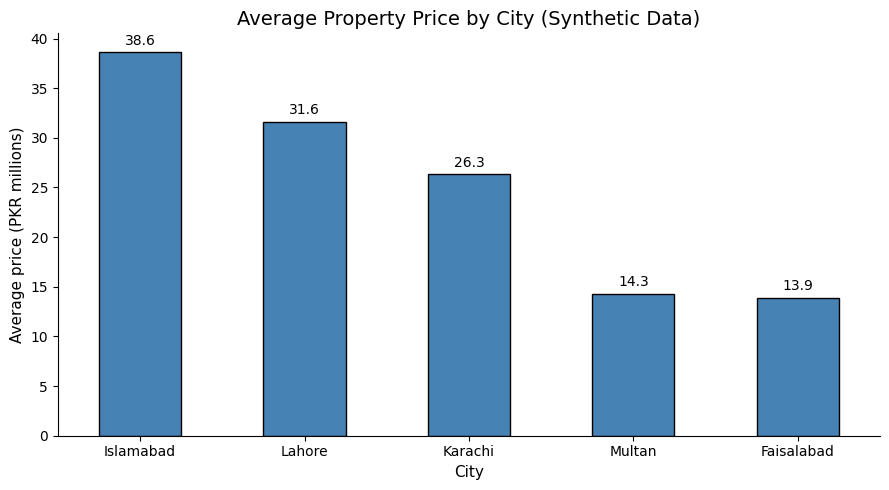

In [ ]:
# Bar chart: average property price per city (in PKR millions)
avg_price_m = price_by_city["mean"] / 1_000_000

ax = avg_price_m.plot(kind="bar", color="steelblue", edgecolor="black")
ax.set_title("Average Property Price by City (Synthetic Data)")
ax.set_xlabel("City")
ax.set_ylabel("Average price (PKR millions)")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/avg_price_by_city.png", dpi=150)
plt.show()

**Result.** Islamabad (PKR 38.6M) and Lahore (PKR 31.6M) lead on average price, followed by Karachi (PKR 26.3M); Multan (PKR 14.3M) and Faisalabad (PKR 13.9M) are less than half the price of Islamabad. Lahore and Karachi also hold the largest inventories (139 and 131 listings). Median size is about the same (5-7 Marla) in every city, so the price gap is mainly a *price level* gap, not a size gap.

### 4.4 City and property-type segmentation

Grouping by two columns shows which city-type combinations drive value. Group sizes are included because averages based on very few listings are unreliable.

In [ ]:
# Group by city AND property_type, with three named aggregations
city_type_summary = (
    df.groupby(["city", "property_type"])
      .agg(mean_price_pkr=("price_pkr", "mean"),
           median_price_per_marla=("price_per_marla", "median"),
           property_count=("property_id", "count"))
)

print("Number of groups:", len(city_type_summary))
print("Total properties:", city_type_summary["property_count"].sum())
city_type_summary.style.format({"mean_price_pkr": "{:,.0f}", "median_price_per_marla": "{:,.0f}"})

Number of groups: 20
Total properties: 495


In [ ]:
# The result has a two-level index (city, property_type); reset_index() makes both normal columns
city_type_flat = city_type_summary.reset_index()

# Smallest groups: statistics based on very few properties are less reliable
city_type_flat.nsmallest(5, "property_count")

,city,property_type,mean_price_pkr,median_price_per_marla,property_count
16,Multan,Commercial,13475000.00,2303125.00,2
0,Faisalabad,Commercial,18010000.00,2525000.00,5
4,Islamabad,Commercial,29414285.71,7400000.00,7
3,Faisalabad,Plot,19429166.67,1343750.00,12
1,Faisalabad,Flat,6061538.46,1250000.00,13


**Detailed report:** average size and average price per Marla for each segment.

In [ ]:
# Segment report: count, average price, average size, average price per Marla
city_type_report = (
    df.groupby(["city", "property_type"])
      .agg(property_count=("property_id", "count"),
           avg_price_pkr=("price_pkr", "mean"),
           avg_area_marla=("area_marla", "mean"),
           avg_price_per_marla=("price_per_marla", "mean"))
      .round({"avg_price_pkr": 0, "avg_area_marla": 1, "avg_price_per_marla": 0})
      .reset_index()
)
city_type_report

,city,property_type,property_count,avg_price_pkr,avg_area_marla,avg_price_per_marla
0,Faisalabad,Commercial,5,18010000.00,7.20,2463750.00
1,Faisalabad,Flat,13,6061538.00,4.40,1361378.00
2,Faisalabad,House,32,14390625.00,9.20,1597206.00
3,Faisalabad,Plot,12,19429167.00,14.40,1324062.00
4,Islamabad,Commercial,7,29414286.00,4.60,6923214.00
5,Islamabad,Flat,29,14610345.00,4.60,3171193.00
6,Islamabad,House,46,42646739.00,10.20,4254532.00
7,Islamabad,Plot,14,79539286.00,20.40,3823661.00
8,Karachi,Commercial,15,46930000.00,8.40,4966472.00
9,Karachi,Flat,31,9046774.00,3.80,2399530.00


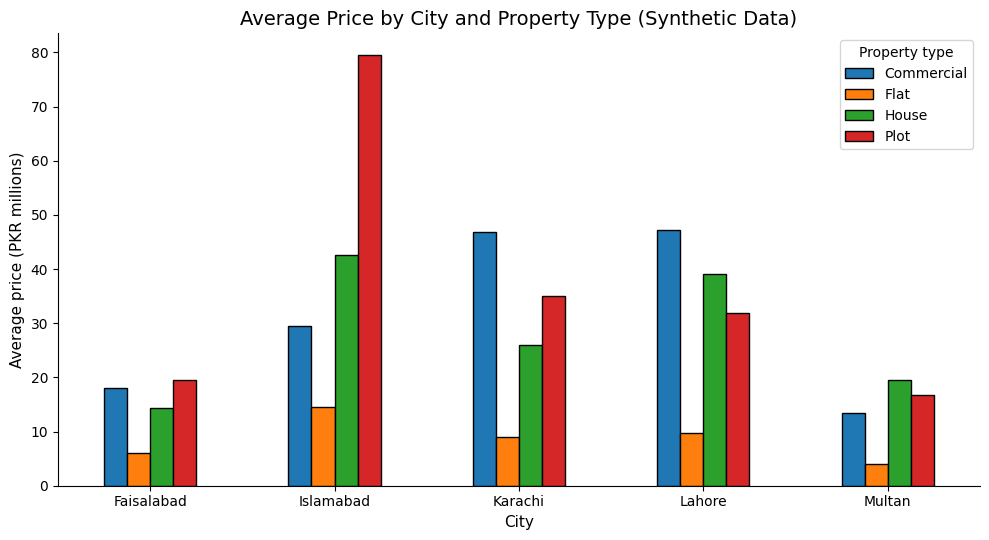

In [ ]:
# Grouped bar chart: average price for each property type inside each city (PKR millions)
pivot_price = (city_type_report
               .pivot(index="city", columns="property_type", values="avg_price_pkr") / 1_000_000)

ax = pivot_price.plot(kind="bar", figsize=(10, 5.5), edgecolor="black")
ax.set_title("Average Price by City and Property Type (Synthetic Data)")
ax.set_xlabel("City")
ax.set_ylabel("Average price (PKR millions)")
ax.legend(title="Property type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/avg_price_by_city_and_type.png", dpi=150)
plt.show()

**Result.**
- Average *total* price depends heavily on size: Islamabad plots (about 20 Marla on average) are the most expensive segment at about PKR 79.5M, and flats are the cheapest type in every city because they are the smallest.
- Average *price per Marla* removes the size effect: **commercial property has the highest price per Marla in every city.**
- The city ranking is not identical for every type: Islamabad leads for houses and plots, but its commercial units are smaller and have a lower average price than those in Karachi or Lahore.
- Some segments are tiny (Multan commercial has 2 listings), so their averages should be read with caution.

### 4.5 Market composition

Counts and percentages for property type, furnishing, seller type and listing status show what the inventory is made of.

In [ ]:
owner_summary = (
    df.groupby("owner_type")
      .agg(min_price_pkr=("price_pkr", "min"),
           max_price_pkr=("price_pkr", "max"),
           mean_price_pkr=("price_pkr", "mean"),
           listings=("property_id", "count"))
      .sort_values("mean_price_pkr", ascending=False)
)
owner_summary.style.format("{:,.0f}")

,min_price_pkr,max_price_pkr,mean_price_pkr,listings
owner_type,,,,
Owner,"1,450,000","188,950,000","28,592,117",222
Unknown,"4,600,000","77,500,000","26,372,222",9
Dealer,"1,950,000","209,850,000","26,137,379",206
Builder,"1,700,000","156,050,000","24,228,448",58


In [ ]:
avg_ppm_by_city = (df.groupby("city")["price_per_marla"]
                     .mean()
                     .sort_values(ascending=False)
                     .rename("avg_price_per_marla"))

top_city = avg_ppm_by_city.idxmax()
print(f"City with the highest average price per Marla: {top_city} "
      f"(PKR {avg_ppm_by_city.max():,.0f} per Marla)")
avg_ppm_by_city.to_frame().style.format("{:,.0f}")

City with the highest average price per Marla: Islamabad (PKR 4,059,029 per Marla)


,avg_price_per_marla
city,
Islamabad,"4,059,029"
Lahore,"3,647,403"
Karachi,"2,903,840"
Faisalabad,"1,564,774"
Multan,"1,319,755"


In [ ]:
# value_counts() with counts and percentages for the four categorical columns
for col in ["property_type", "furnished", "owner_type", "status"]:
    counts = df[col].value_counts()
    summary = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})
    print(f"--- {col} ---")
    display(summary)

--- property_type ---


,count,percent
property_type,,
House,235,47.50
Flat,127,25.70
Plot,88,17.80
Commercial,45,9.10


--- furnished ---


,count,percent
furnished,,
No,365,73.70
Yes,130,26.30


--- owner_type ---


,count,percent
owner_type,,
Owner,222,44.80
Dealer,206,41.60
Builder,58,11.70
Unknown,9,1.80


--- status ---


,count,percent
status,,
Available,275,55.60
Sold,152,30.70
Pending,68,13.70


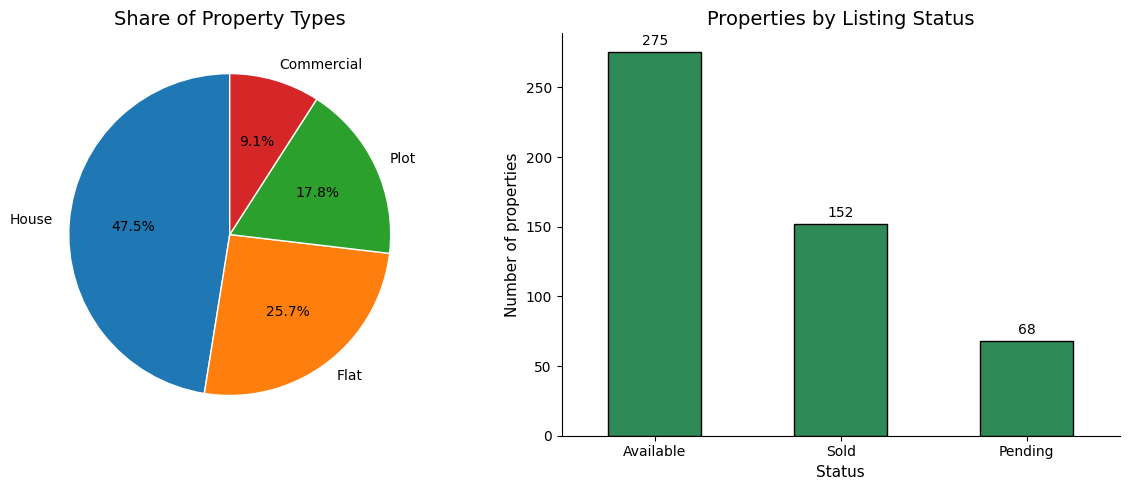

Dominant property type: House


In [ ]:
# Two charts: property types (pie) and listing status (bar)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["property_type"].value_counts().plot(
    kind="pie", ax=axes[0], autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white"})
axes[0].set_title("Share of Property Types")
axes[0].set_ylabel("")

status_counts = df["status"].value_counts()
status_counts.plot(kind="bar", ax=axes[1], color="seagreen", edgecolor="black")
axes[1].set_title("Properties by Listing Status")
axes[1].set_xlabel("Status")
axes[1].set_ylabel("Number of properties")
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/property_type_and_status.png", dpi=150)
plt.show()

print("Dominant property type:", df["property_type"].value_counts().idxmax())

**Result.**
- **House** dominates the inventory (47.5%), followed by flats (25.7%), plots (17.8%) and commercial units (9.1%).
- 55.6% of listings are Available, 30.7% Sold and 13.7% Pending.
- Islamabad has the highest average price per Marla (about PKR 4.06M).
- Differences in price between seller types (owner, dealer, builder) should not be read as causal: each seller type may simply handle different cities and property types.

### 4.6 Price and size distributions

Histograms and box plots show the shape and spread of the market and its outliers.

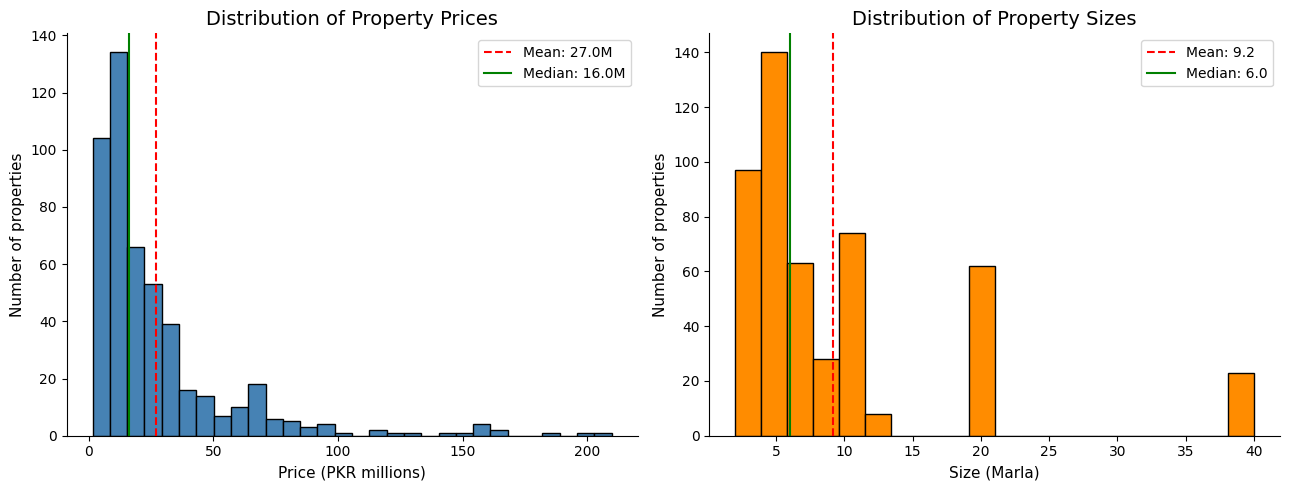

In [ ]:
import matplotlib.dates as mdates

price_m = df["price_pkr"] / 1_000_000          # price in PKR millions

# Histograms of price and size
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(price_m, bins=30, color="steelblue", edgecolor="black")
axes[0].axvline(price_m.mean(), color="red", linestyle="--", label=f"Mean: {price_m.mean():.1f}M")
axes[0].axvline(price_m.median(), color="green", linestyle="-", label=f"Median: {price_m.median():.1f}M")
axes[0].set_title("Distribution of Property Prices")
axes[0].set_xlabel("Price (PKR millions)")
axes[0].set_ylabel("Number of properties")
axes[0].legend()

axes[1].hist(df["area_marla"], bins=20, color="darkorange", edgecolor="black")
axes[1].axvline(df["area_marla"].mean(), color="red", linestyle="--", label=f"Mean: {df['area_marla'].mean():.1f}")
axes[1].axvline(df["area_marla"].median(), color="green", linestyle="-", label=f"Median: {df['area_marla'].median():.1f}")
axes[1].set_title("Distribution of Property Sizes")
axes[1].set_xlabel("Size (Marla)")
axes[1].set_ylabel("Number of properties")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_size_distributions.png", dpi=150)
plt.show()

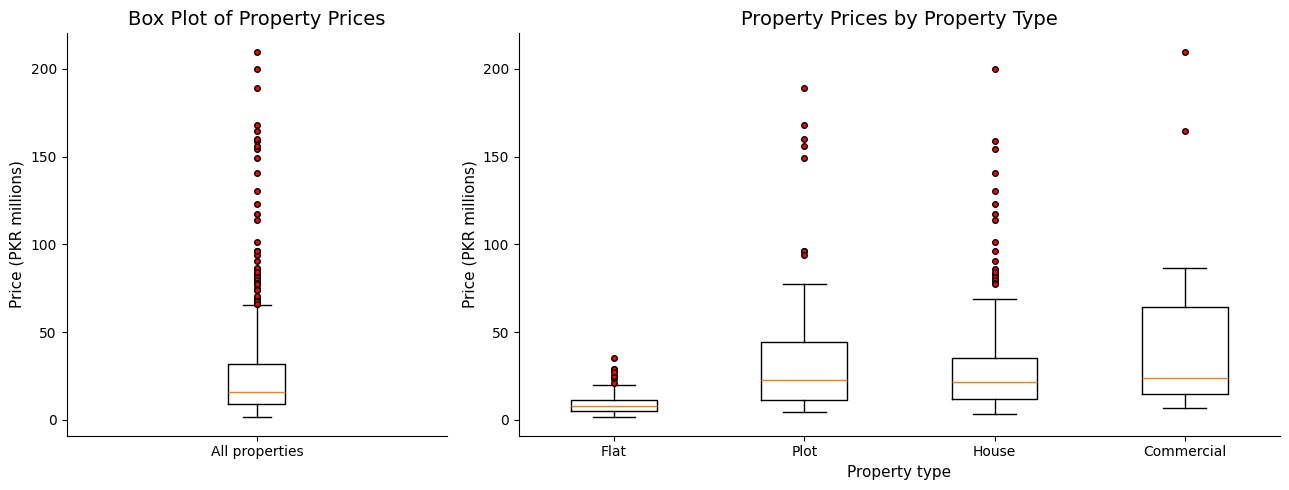

In [ ]:
# Box plots: overall price, and price by property type
order = ["Flat", "Plot", "House", "Commercial"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 2]})

axes[0].boxplot(price_m, flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 4})
axes[0].set_xticks([1], ["All properties"])
axes[0].set_title("Box Plot of Property Prices")
axes[0].set_ylabel("Price (PKR millions)")

groups = [price_m[df["property_type"] == t] for t in order]
axes[1].boxplot(groups, flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 4})
axes[1].set_xticks(range(1, len(order) + 1), order)
axes[1].set_title("Property Prices by Property Type")
axes[1].set_xlabel("Property type")
axes[1].set_ylabel("Price (PKR millions)")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_boxplots.png", dpi=150)
plt.show()

In [ ]:
# Numbers behind the charts: skewness and outliers (IQR rule: above Q3 + 1.5 x IQR)
q1, q3 = price_m.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_outliers = (price_m > upper_fence).sum()

print(f"Mean price   : {price_m.mean():.1f}M | Median price: {price_m.median():.1f}M")
print(f"Skewness of price: {price_m.skew():.2f} (positive = long tail to the right)")
print(f"Q1 = {q1:.1f}M, Q3 = {q3:.1f}M, IQR = {iqr:.1f}M, upper fence = {upper_fence:.1f}M")
print(f"High-price outliers: {n_outliers} properties ({n_outliers / len(df) * 100:.1f}%)")

# Spread by property type
price_m.groupby(df["property_type"]).agg(["median", "mean", "std", "max"]).round(1).loc[order]

Mean price   : 27.0M | Median price: 16.0M
Skewness of price: 2.86 (positive = long tail to the right)
Q1 = 9.2M, Q3 = 31.9M, IQR = 22.7M, upper fence = 65.8M
High-price outliers: 45 properties (9.1%)


,median,mean,std,max
property_type,,,,
Flat,8.00,9.40,6.10,35.00
Plot,23.00,36.20,38.60,189.00
House,21.80,30.70,29.40,199.90
Commercial,23.80,39.60,40.10,209.80


**Result.**
- **Prices are right-skewed**: most listings are in the lower range, with a long tail of very expensive properties (mean PKR 27.0M vs median PKR 16.0M).
- **45 listings (9.1%)** are high-price outliers by the IQR rule. They are genuine large or commercial properties, not errors, so they are kept, but averages should always be read next to medians.
- Flats have the lowest and tightest prices; houses, plots and commercial properties have higher medians and a much wider spread because their sizes vary widely.
- Most properties are small or medium; a few large 20 and 40 Marla properties stretch the size distribution.

### 4.7 Price drivers

Scatter plots and a correlation matrix show which variables move with price.

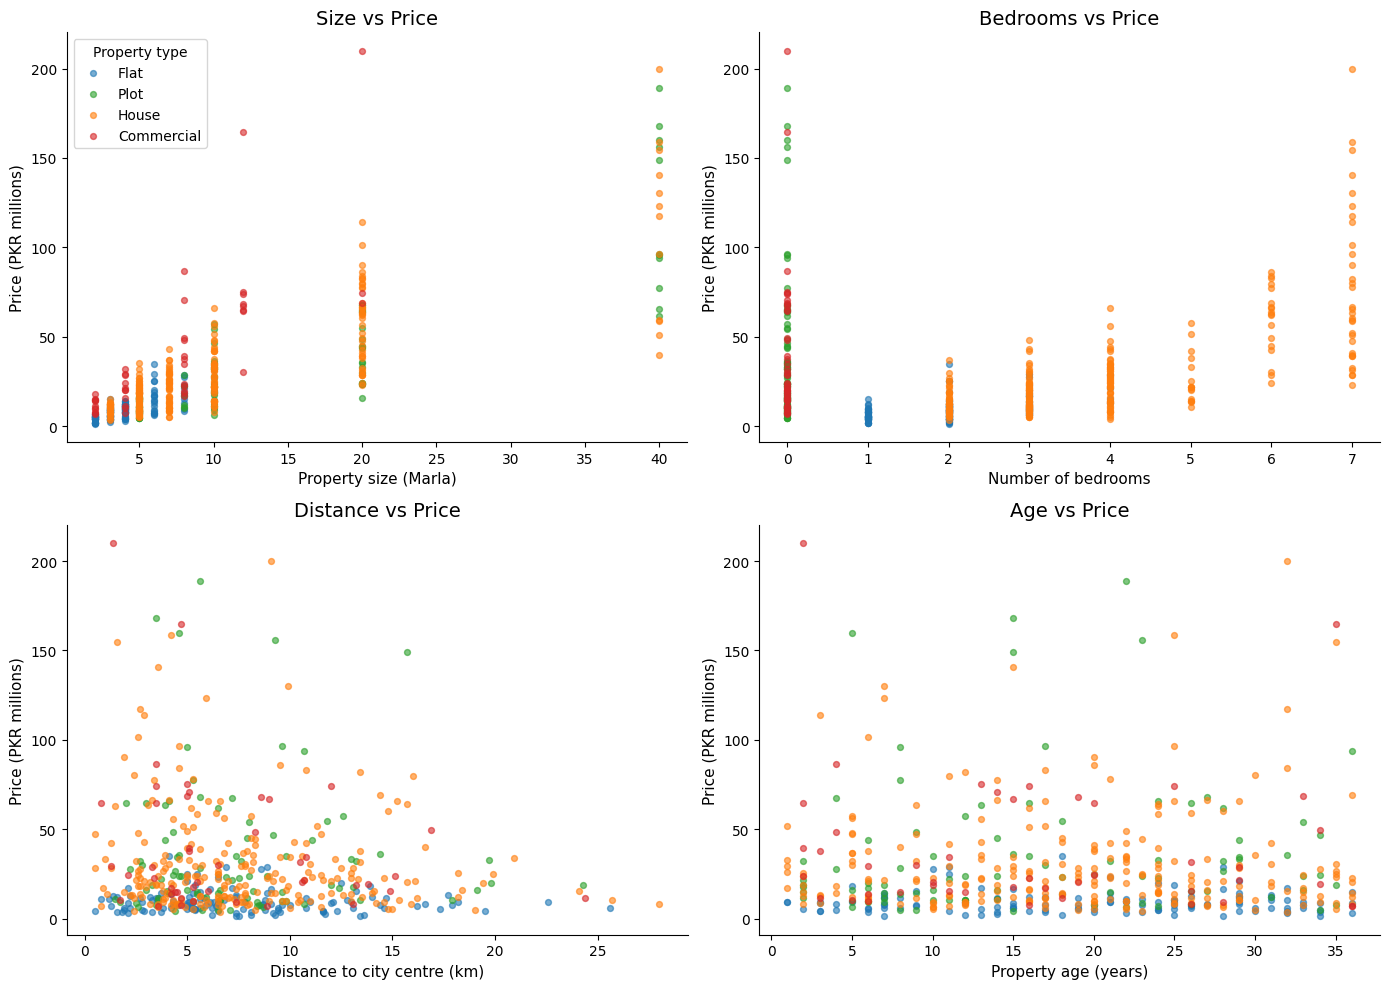

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = {"Flat": "tab:blue", "Plot": "tab:green", "House": "tab:orange", "Commercial": "tab:red"}

pairs = [
    ("area_marla", "Property size (Marla)", "Size vs Price"),
    ("bedrooms", "Number of bedrooms", "Bedrooms vs Price"),
    ("distance_to_city_center_km", "Distance to city centre (km)", "Distance vs Price"),
    ("property_age", "Property age (years)", "Age vs Price"),
]

for ax, (col, xlabel, title) in zip(axes.ravel(), pairs):
    for ptype, color in colors.items():
        subset = df[df["property_type"] == ptype]
        ax.scatter(subset[col], subset["price_pkr"] / 1_000_000,
                   s=18, alpha=0.6, color=color, label=ptype)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Price (PKR millions)")
axes[0, 0].legend(title="Property type")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_drivers_scatter.png", dpi=150)
plt.show()

In [ ]:
corr_cols = ["price_pkr", "area_marla", "bedrooms", "bathrooms",
             "parking_spaces", "distance_to_city_center_km", "property_age"]
corr = df[corr_cols].corr()
corr.round(2)

,price_pkr,area_marla,bedrooms,bathrooms,parking_spaces,distance_to_city_center_km,property_age
price_pkr,1.00,0.81,0.23,0.25,0.10,-0.10,-0.01
area_marla,0.81,1.00,0.32,0.24,0.06,-0.04,0.03
bedrooms,0.23,0.32,1.00,0.89,0.50,-0.01,0.09
bathrooms,0.25,0.24,0.89,1.00,0.58,-0.01,0.11
parking_spaces,0.10,0.06,0.50,0.58,1.00,0.00,0.03
distance_to_city_center_km,-0.10,-0.04,-0.01,-0.01,0.00,1.00,-0.03
property_age,-0.01,0.03,0.09,0.11,0.03,-0.03,1.00


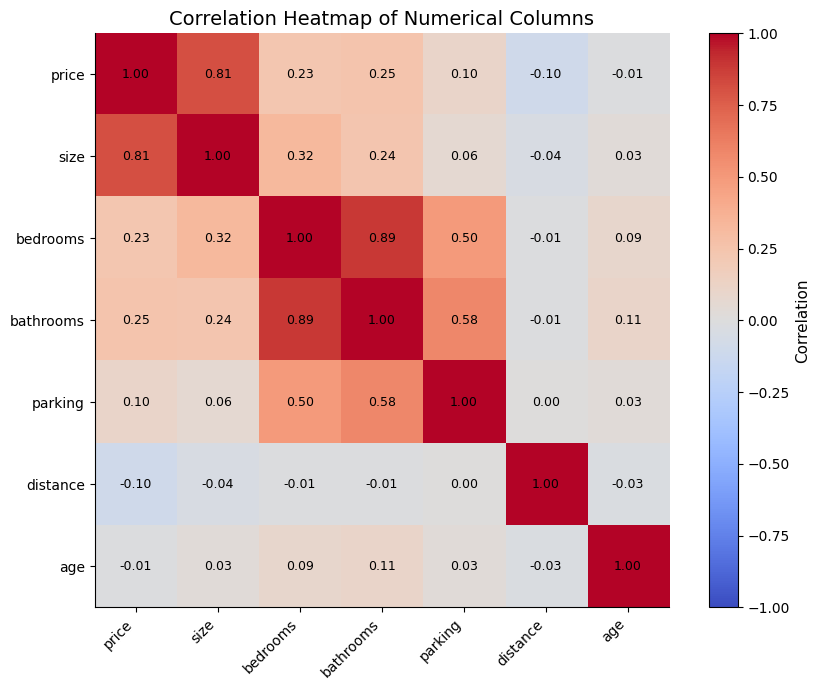

In [ ]:
# Heatmap of the correlation matrix (drawn with matplotlib)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

short_names = ["price", "size", "bedrooms", "bathrooms", "parking", "distance", "age"]
ax.set_xticks(range(len(short_names)), short_names, rotation=45, ha="right")
ax.set_yticks(range(len(short_names)), short_names)

# Write the correlation value inside each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)

ax.set_title("Correlation Heatmap of Numerical Columns")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=150)
plt.show()

In [ ]:
# Correlation of each variable with price, strongest first
print("Correlation with price_pkr:")
print(corr["price_pkr"].drop("price_pkr").sort_values(ascending=False).round(2))

# Price per Marla removes the size effect, so location and age effects are easier to see
print("\nCorrelation with price_per_marla:")
print(df[["price_per_marla", "distance_to_city_center_km", "property_age"]].corr()["price_per_marla"].drop("price_per_marla").round(2))

Correlation with price_pkr:
area_marla                    0.81
bathrooms                     0.25
bedrooms                      0.23
parking_spaces                0.10
property_age                 -0.01
distance_to_city_center_km   -0.10
Name: price_pkr, dtype: float64

Correlation with price_per_marla:
distance_to_city_center_km   -0.14
property_age                 -0.12
Name: price_per_marla, dtype: float64


**Result.**
- **Size is the only strong driver** of total price (correlation 0.81).
- Bedrooms (0.23) and bathrooms (0.25) are weakly related to price, partly because bigger properties have more rooms.
- Distance to the city centre (-0.10) and age (-0.01) have almost no relationship with total price; against price per Marla they are slightly stronger (-0.14 and -0.12) but still weak.
- **Correlation is not causation.** Bedrooms and price move together mainly because both depend on property size (a confounding variable). Correlation also captures only linear relationships and can be distorted by outliers.

### 4.8 Listing trends over time

Using `listing_date` as the index, `resample("MS")` aggregates listings and prices by calendar month.

In [ ]:
# Index by date so that resample() can group by month
ts = df.set_index("listing_date").sort_index()

monthly_listings = ts["property_id"].resample("MS").count()      # listings per month
monthly_avg_price = ts["price_pkr"].resample("MS").mean()        # average price per month

monthly = pd.DataFrame({"listings": monthly_listings, "avg_price_pkr": monthly_avg_price.round(0)})
monthly.index = monthly.index.strftime("%b %Y")                  # readable month labels
print("Number of months:", len(monthly))
monthly

Number of months: 21


,listings,avg_price_pkr
listing_date,,
Jan 2025,29,16712069.00
Feb 2025,15,21620000.00
Mar 2025,30,34615000.00
Apr 2025,28,17496429.00
May 2025,25,26640000.00
Jun 2025,19,37326316.00
Jul 2025,21,17676190.00
Aug 2025,29,38741379.00
Sep 2025,21,27866667.00


In [ ]:
busiest_month = monthly_listings.idxmax()
print(f"Month with the most listings: {busiest_month.strftime('%B %Y')} ({monthly_listings.max()} listings)")
print(f"Month with the fewest listings: {monthly_listings.idxmin().strftime('%B %Y')} ({monthly_listings.min()} listings)")
print(f"Average listings per month: {monthly_listings.mean():.1f}")

Month with the most listings: June 2026 (33 listings)
Month with the fewest listings: February 2025 (15 listings)
Average listings per month: 23.6


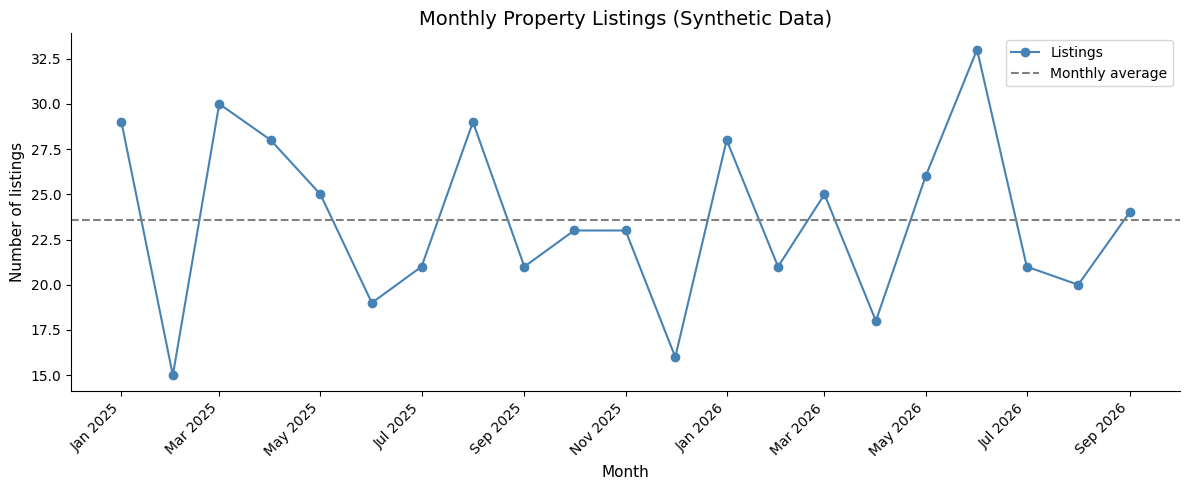

In [ ]:
# Line chart: monthly listing counts
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_listings.index, monthly_listings.values, marker="o", color="steelblue", label="Listings")
ax.axhline(monthly_listings.mean(), color="gray", linestyle="--", label="Monthly average")
ax.set_title("Monthly Property Listings (Synthetic Data)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of listings")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/monthly_listings.png", dpi=150)
plt.show()

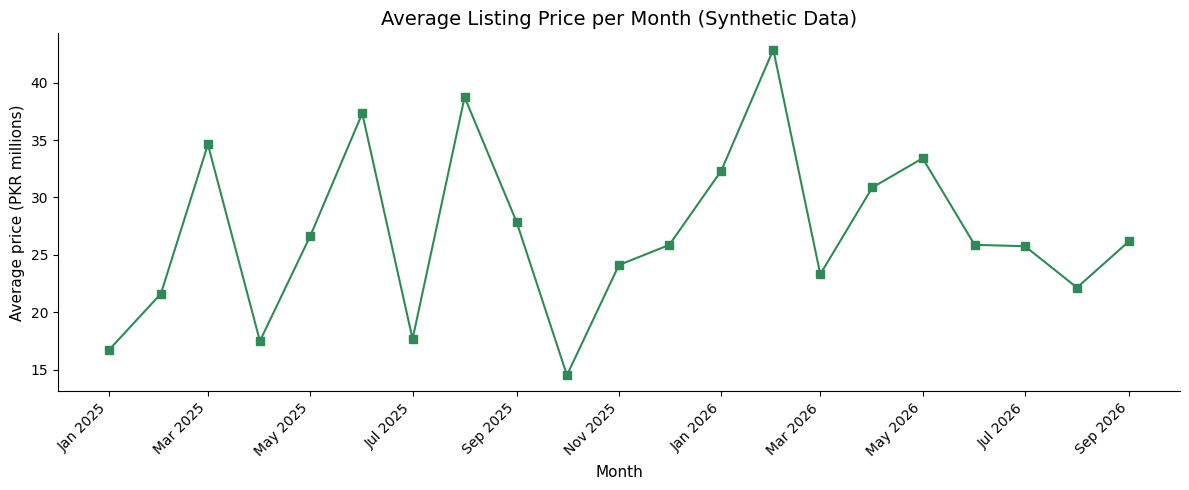

In [ ]:
# Line chart: average listing price per month (PKR millions)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_avg_price.index, monthly_avg_price.values / 1_000_000, marker="s", color="seagreen")
ax.set_title("Average Listing Price per Month (Synthetic Data)")
ax.set_xlabel("Month")
ax.set_ylabel("Average price (PKR millions)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/monthly_avg_price.png", dpi=150)
plt.show()

In [ ]:
# Is there a real trend? Fit a straight line to the monthly counts and prices
x = np.arange(len(monthly_listings))
slope_listings = np.polyfit(x, monthly_listings.values, 1)[0]
slope_price = np.polyfit(x, monthly_avg_price.values / 1_000_000, 1)[0]

half = len(monthly_listings) // 2
print(f"Listings trend: {slope_listings:+.2f} listings per month")
print(f"Average price trend: {slope_price:+.2f} PKR million per month")
print(f"Avg monthly listings, first {half} months: {monthly_listings.iloc[:half].mean():.1f} | "
      f"remaining months: {monthly_listings.iloc[half:].mean():.1f}")
print(f"Monthly listings range: {monthly_listings.min()} to {monthly_listings.max()}")

Listings trend: -0.05 listings per month
Average price trend: +0.20 PKR million per month
Avg monthly listings, first 10 months: 24.0 | remaining months: 23.2
Monthly listings range: 15 to 33


**Result.**
- Monthly listings range from 15 to 33 (average 23.6); the busiest month is June 2026.
- The fitted trend is almost flat (-0.05 listings per month) and the first and second halves of the period have similar monthly averages: **no clear growth or decline**.
- Monthly average price swings widely (roughly PKR 15M to 43M) because only about 24 listings fall in each month, so a few expensive properties move the average.
- Listing dates in this dataset were generated randomly, so no real seasonality can be claimed; real data would need several years to separate seasonal patterns from noise.

---
## 5. Advanced Insights

### 5.1 Pivot tables and cross-tabulation

A pivot table summarises price by city and property type; a cross-tabulation counts listing status by city. Averages are only trusted for segments with at least 5 listings.

In [ ]:
# Pivot table: average price (rows = city, columns = property type); margins add the "All" totals
pivot_avg_price = pd.pivot_table(df, values="price_pkr", index="city",
                                 columns="property_type", aggfunc="mean")
pivot_with_totals = pd.pivot_table(df, values="price_pkr", index="city",
                                   columns="property_type", aggfunc="mean",
                                   margins=True, margins_name="All")
pivot_with_totals.style.format("{:,.0f}")

property_type,Commercial,Flat,House,Plot,All
city,,,,,
Faisalabad,"18,010,000","6,061,538","14,390,625","19,429,167","13,911,290"
Islamabad,"29,414,286","14,610,345","42,646,739","79,539,286","38,592,708"
Karachi,"46,930,000","9,046,774","26,027,193","35,107,143","26,343,130"
Lahore,"47,203,125","9,660,000","39,108,696","31,826,316","31,629,856"
Multan,"13,475,000","3,973,684","19,520,968","16,790,000","14,320,149"
All,"39,602,222","9,421,654","30,678,511","36,207,386","27,018,889"


In [ ]:
# Number of properties in each cell, to judge how reliable each average is
pivot_counts = pd.pivot_table(df, values="property_id", index="city",
                              columns="property_type", aggfunc="count")
pivot_counts

property_type,Commercial,Flat,House,Plot
city,,,,
Faisalabad,5,13,32,12
Islamabad,7,29,46,14
Karachi,15,31,57,28
Lahore,16,35,69,19
Multan,2,19,31,15


In [ ]:
# Cross-tabulation: city vs listing status (counts, then row percentages)
crosstab_counts = pd.crosstab(df["city"], df["status"], margins=True, margins_name="All")
print("Counts:")
display(crosstab_counts)

crosstab_pct = (pd.crosstab(df["city"], df["status"], normalize="index") * 100).round(1)
print("Percentage of each city's listings by status:")
crosstab_pct

Counts:


status,Available,Pending,Sold,All
city,,,,
Faisalabad,33,9,20,62
Islamabad,56,10,30,96
Karachi,72,18,41,131
Lahore,81,17,41,139
Multan,33,14,20,67
All,275,68,152,495


Percentage of each city's listings by status:


status,Available,Pending,Sold
city,,,
Faisalabad,53.20,14.50,32.30
Islamabad,58.30,10.40,31.20
Karachi,55.00,13.70,31.30
Lahore,58.30,12.20,29.50
Multan,49.30,20.90,29.90


In [ ]:
# City with the highest average price for each property type,
# only using groups with enough data (at least MIN_COUNT properties)
MIN_COUNT = 5
reliable_avg = pivot_avg_price.where(pivot_counts >= MIN_COUNT)   # NaN where the group is too small

best_cities = pd.DataFrame({
    "top_city": reliable_avg.idxmax(),
    "avg_price_pkr": reliable_avg.max(),
})
best_cities["properties_in_group"] = [pivot_counts.loc[c, t] for t, c in best_cities["top_city"].items()]
best_cities.style.format({"avg_price_pkr": "{:,.0f}"})

,top_city,avg_price_pkr,properties_in_group
property_type,,,
Commercial,Lahore,"47,203,125",16
Flat,Islamabad,"14,610,345",29
House,Islamabad,"42,646,739",46
Plot,Islamabad,"79,539,286",14


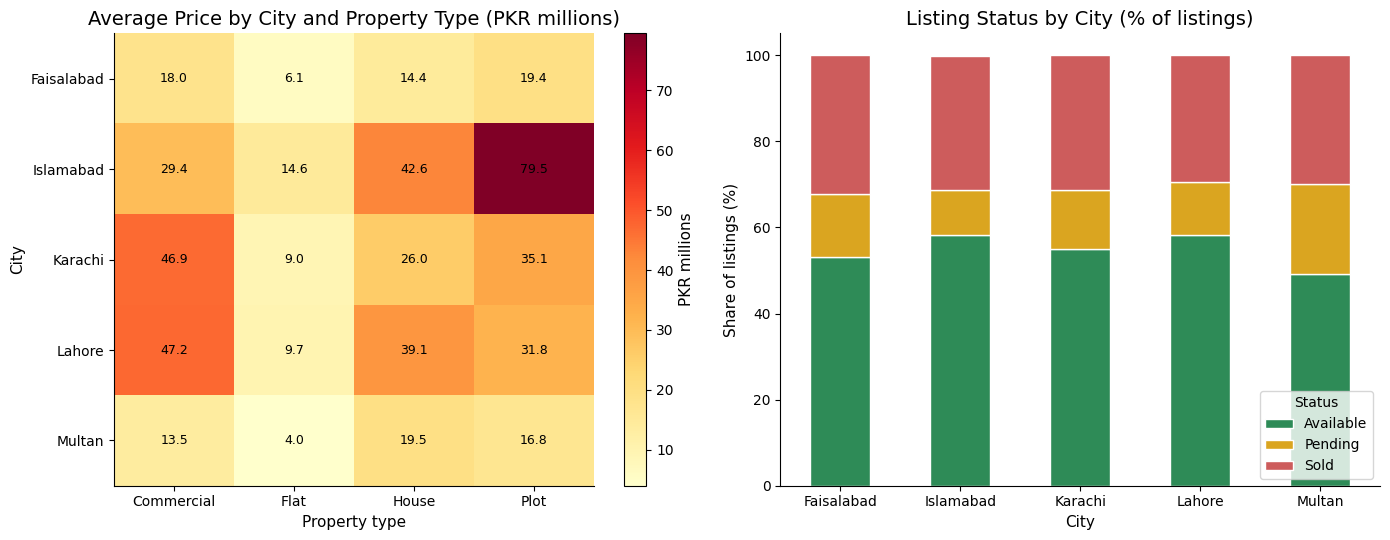

In [ ]:
# Charts: pivot table heatmap (PKR millions) and listing status by city
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

pm = pivot_avg_price / 1_000_000
im = axes[0].imshow(pm, cmap="YlOrRd", aspect="auto")
axes[0].set_xticks(range(pm.shape[1]), pm.columns)
axes[0].set_yticks(range(pm.shape[0]), pm.index)
for i in range(pm.shape[0]):
    for j in range(pm.shape[1]):
        axes[0].text(j, i, f"{pm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=9)
axes[0].set_title("Average Price by City and Property Type (PKR millions)")
axes[0].set_xlabel("Property type")
axes[0].set_ylabel("City")
fig.colorbar(im, ax=axes[0], label="PKR millions")

crosstab_pct.plot(kind="bar", stacked=True, ax=axes[1], edgecolor="white",
                  color=["seagreen", "goldenrod", "indianred"])
axes[1].set_title("Listing Status by City (% of listings)")
axes[1].set_xlabel("City")
axes[1].set_ylabel("Share of listings (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Status", loc="lower right")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/pivot_and_status.png", dpi=150)
plt.show()

**Result.**
- **Islamabad has the highest average price for flats, houses and plots; Lahore leads for commercial property.** Multan commercial (2 listings) was excluded for lack of data.
- Listing status differs by city: Multan has the largest share of Pending listings (20.9%) and the smallest share of Available ones (49.3%), compared with 10-15% Pending elsewhere. With only 67 Multan listings this is a pointer for follow-up, not a firm conclusion.

### 5.2 Price segmentation

Listings are classified into four price bands. The thresholds are based on the price distribution in section 4.6 (median about PKR 16M; the middle half of listings lies between roughly PKR 9M and 32M).

| Segment | Price range |
|---|---|
| Budget | below PKR 10 million |
| Mid-range | PKR 10 million to below 30 million |
| Premium | PKR 30 million to below 70 million |
| Luxury | PKR 70 million and above |

The function-based version (`apply`) is cross-checked against a vectorized `pd.cut()` version; `map` converts furnished flags into readable labels.

In [ ]:
def classify_price(price):
    """Return the price category of one property (price in PKR)."""
    if price < 10_000_000:
        return "Budget"
    elif price < 30_000_000:
        return "Mid-range"
    elif price < 70_000_000:
        return "Premium"
    else:
        return "Luxury"

# apply() runs the function on every price
df["price_category"] = df["price_pkr"].apply(classify_price)

# Cross-check with a vectorized version (pd.cut): both must give the same result
bins = [0, 10_000_000, 30_000_000, 70_000_000, float("inf")]
labels = ["Budget", "Mid-range", "Premium", "Luxury"]
check = pd.cut(df["price_pkr"], bins=bins, labels=labels, right=False).astype(str)
print("apply() and pd.cut() agree:", (check == df["price_category"]).all())

apply() and pd.cut() agree: True


In [ ]:
# map(): convert Yes/No to descriptive labels
df["furnished_label"] = df["furnished"].map({"Yes": "Furnished", "No": "Unfurnished"})

# Compare the number of properties in each price category (in logical order)
category_counts = (df["price_category"].value_counts().reindex(labels)
                   .rename("properties").to_frame())
category_counts["percent"] = (category_counts["properties"] / len(df) * 100).round(1)
category_counts

,properties,percent
price_category,,
Budget,145,29.30
Mid-range,218,44.00
Premium,97,19.60
Luxury,35,7.10


In [ ]:
# Price category vs furnished status
pd.crosstab(df["price_category"], df["furnished_label"]).reindex(labels)

furnished_label,Furnished,Unfurnished
price_category,,
Budget,47,98
Mid-range,50,168
Premium,21,76
Luxury,12,23


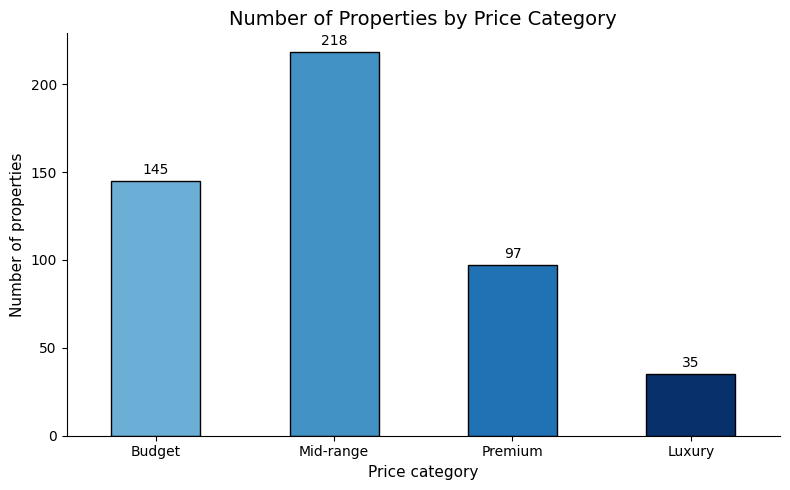

In [ ]:
# Bar chart of the price categories
ax = category_counts["properties"].plot(kind="bar", color=["#6baed6", "#4292c6", "#2171b5", "#08306b"],
                                        edgecolor="black", figsize=(8, 5))
ax.set_title("Number of Properties by Price Category")
ax.set_xlabel("Price category")
ax.set_ylabel("Number of properties")
ax.bar_label(ax.containers[0], padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_categories.png", dpi=150)
plt.show()

**Result.** The inventory is centred on the **mid-range (44.0%, 218 listings)**, followed by Budget (29.3%), Premium (19.6%) and Luxury (7.1%, 35 listings). The thresholds are a business choice, so segment sizes change if they are changed; the vectorized version is the better choice on large data.

### 5.3 Macro context: city income versus property prices

A small city-level table (region, population, average income) is merged onto the listings with a left join (`validate="many_to_one"` guards against duplicate cities). **These city values are illustrative and synthetic**: populations are rounded approximations and incomes are made up for this exercise.

In [ ]:
city_info = pd.DataFrame({
    "city": ["Lahore", "Karachi", "Islamabad", "Faisalabad", "Multan"],
    "region": ["Punjab", "Sindh", "Islamabad Capital Territory", "Punjab", "Punjab"],
    "population_millions": [13.0, 20.4, 1.2, 3.7, 2.2],                 # approximate, rounded
    "average_income_pkr": [120_000, 115_000, 180_000, 85_000, 75_000],   # synthetic monthly household income
})
city_info

,city,region,population_millions,average_income_pkr
0,Lahore,Punjab,13.00,120000
1,Karachi,Sindh,20.40,115000
2,Islamabad,Islamabad Capital Territory,1.20,180000
3,Faisalabad,Punjab,3.70,85000
4,Multan,Punjab,2.20,75000


In [ ]:
# Left merge: keep every property and attach its city information.
# validate="many_to_one" raises an error if city_info had duplicate cities.
df_merged = df.merge(city_info, on="city", how="left", validate="many_to_one")

print("Shape before:", df.shape, "| after:", df_merged.shape)
print("Properties without city information:", int(df_merged["region"].isna().sum()))
df_merged[["property_id", "city", "region", "population_millions", "average_income_pkr", "price_pkr"]].head()

Shape before: (495, 21) | after: (495, 24)
Properties without city information: 0


,property_id,city,region,population_millions,average_income_pkr,price_pkr
0,PK-0001,Islamabad,Islamabad Capital Territory,1.20,180000,65900000
1,PK-0002,Faisalabad,Punjab,3.70,85000,22500000
2,PK-0003,Lahore,Punjab,13.00,120000,49450000
3,PK-0004,Lahore,Punjab,13.00,120000,66650000
4,PK-0005,Multan,Punjab,2.20,75000,5300000


In [ ]:
# City-level table: income vs average property price
city_level = (df_merged
    .groupby(["city", "region", "population_millions", "average_income_pkr"])
    .agg(avg_price_pkr=("price_pkr", "mean"),
         avg_price_per_marla=("price_per_marla", "mean"),
         listings=("property_id", "count"))
    .reset_index()
    .sort_values("average_income_pkr", ascending=False))
display(city_level.style.format({"avg_price_pkr": "{:,.0f}", "avg_price_per_marla": "{:,.0f}",
                                 "average_income_pkr": "{:,.0f}"}))

corr_price = city_level["average_income_pkr"].corr(city_level["avg_price_pkr"])
corr_ppm = city_level["average_income_pkr"].corr(city_level["avg_price_per_marla"])
print(f"Correlation: income vs average price          = {corr_price:.2f}")
print(f"Correlation: income vs average price per Marla = {corr_ppm:.2f}")

,city,region,population_millions,average_income_pkr,avg_price_pkr,avg_price_per_marla,listings
1,Islamabad,Islamabad Capital Territory,1.200000,"180,000","38,592,708","4,059,029",96
3,Lahore,Punjab,13.000000,"120,000","31,629,856","3,647,403",139
2,Karachi,Sindh,20.400000,"115,000","26,343,130","2,903,840",131
0,Faisalabad,Punjab,3.700000,"85,000","13,911,290","1,564,774",62
4,Multan,Punjab,2.200000,"75,000","14,320,149","1,319,755",67


Correlation: income vs average price          = 0.94
Correlation: income vs average price per Marla = 0.91


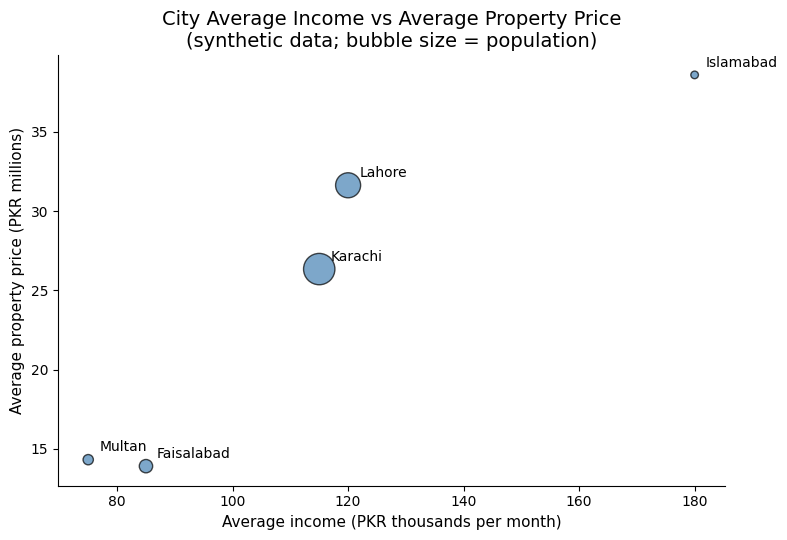

In [ ]:
# Scatter plot: city income vs average property price
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(city_level["average_income_pkr"] / 1000, city_level["avg_price_pkr"] / 1_000_000,
           s=city_level["population_millions"] * 25, color="steelblue", alpha=0.7, edgecolor="black")
for _, row in city_level.iterrows():
    ax.annotate(row["city"], (row["average_income_pkr"] / 1000, row["avg_price_pkr"] / 1_000_000),
                textcoords="offset points", xytext=(8, 6))
ax.set_title("City Average Income vs Average Property Price\n(synthetic data; bubble size = population)")
ax.set_xlabel("Average income (PKR thousands per month)")
ax.set_ylabel("Average property price (PKR millions)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/income_vs_price.png", dpi=150)
plt.show()

**Result and limitations.**
- In this dataset higher-income cities also have higher average prices (correlation about 0.94, and about 0.91 for price per Marla). **This is not a finding**: the incomes were invented and the prices were generated with city price levels chosen by us, so the two were never independent.
- Other limits would apply even with real data: only 5 cities (a correlation on 5 points is very unstable), city averages hide differences within cities, average price depends on the property mix listed in each city, and correlation does not show that income *causes* higher prices.
- The merge keeps all 495 listings and adds the city attributes, which is the pattern to reuse with real economic data.

---
## 6. Business Recommendations, Deliverables and Limitations

This section recalculates every figure used in the report directly from the data, so the insights always match the dataset.

### 6.1 Key figures

In [ ]:
# ---- Data-quality figures ----
n_loaded = len(df_raw)                        # rows loaded from the CSV (500)
missing_cells = int(df_raw.isna().sum().sum())
n_dup_removed = n_removed                     # duplicates removed during cleaning
n_analyzed = len(df)

# ---- Price statistics ----
price_stats = df["price_pkr"].agg(["mean", "median", "min", "max"])

# ---- City comparisons ----
avg_price_city = df.groupby("city")["price_pkr"].mean().sort_values(ascending=False)
ppm_city = df.groupby("city")["price_per_marla"].mean().sort_values(ascending=False)
top_city, cheapest_city = avg_price_city.index[0], avg_price_city.index[-1]

# ---- Property types ----
type_share = df["property_type"].value_counts(normalize=True) * 100
top_type = type_share.index[0]
ppm_type = df.groupby("property_type")["price_per_marla"].median().sort_values(ascending=False)

# ---- Other figures ----
corr_size = df["price_pkr"].corr(df["area_marla"])
corr_dist = df["price_pkr"].corr(df["distance_to_city_center_km"])
status_share = df["status"].value_counts(normalize=True) * 100
busiest = monthly_listings.idxmax()
category_share = category_counts["percent"]

print(f"Properties analysed: {n_analyzed} (loaded {n_loaded}, removed {n_dup_removed} duplicates, filled {missing_cells} missing cells)")
print(f"Price (PKR): mean {price_stats['mean']:,.0f} | median {price_stats['median']:,.0f} | min {price_stats['min']:,.0f} | max {price_stats['max']:,.0f}")
print(f"Most expensive city (avg price): {top_city} | most affordable: {cheapest_city}")
print(f"Most common property type: {top_type} ({type_share.iloc[0]:.1f}%)")

Properties analysed: 495 (loaded 500, removed 5 duplicates, filled 113 missing cells)
Price (PKR): mean 27,018,889 | median 16,000,000 | min 1,450,000 | max 209,850,000
Most expensive city (avg price): Islamabad | most affordable: Faisalabad
Most common property type: House (47.5%)


### 6.2 Business insights and recommendations

In [ ]:
# Every insight below uses numbers calculated above
insights = [
    f"Data quality: {n_loaded} records were loaded; {missing_cells} missing cells were filled and "
    f"{n_dup_removed} duplicate listings were removed, leaving {n_analyzed} properties for analysis.",

    f"Prices are strongly right-skewed: the average price (PKR {price_stats['mean']/1e6:.1f}M) is well above "
    f"the median (PKR {price_stats['median']/1e6:.1f}M) because a few very expensive properties pull the mean up.",

    f"{top_city} has the highest average property price (PKR {avg_price_city.iloc[0]/1e6:.1f}M) and "
    f"{cheapest_city} the lowest (PKR {avg_price_city.iloc[-1]/1e6:.1f}M). By price per Marla, "
    f"{ppm_city.index[0]} is the most expensive city (PKR {ppm_city.iloc[0]/1e6:.2f}M per Marla).",

    f"{top_type} is the most common property type ({type_share.iloc[0]:.1f}% of listings), while "
    f"{ppm_type.index[0]} properties have the highest median price per Marla (PKR {ppm_type.iloc[0]/1e6:.2f}M).",

    f"Size is the main price driver: the correlation between size and price is {corr_size:.2f}, "
    f"while distance to the city centre ({corr_dist:.2f}) is only weakly related to total price.",

    f"{status_share.get('Available', 0):.1f}% of properties are Available, {status_share.get('Sold', 0):.1f}% Sold "
    f"and {status_share.get('Pending', 0):.1f}% Pending.",

    f"{category_share['Mid-range']:.1f}% of properties are Mid-range (PKR 10M to 30M), compared with "
    f"{category_share['Budget']:.1f}% Budget, {category_share['Premium']:.1f}% Premium and {category_share['Luxury']:.1f}% Luxury.",

    f"Monthly listings range from {monthly_listings.min()} to {monthly_listings.max()} (busiest month: "
    f"{busiest.strftime('%B %Y')}) with no clear upward or downward trend ({slope_listings:+.2f} listings per month).",
]

recommendations = [
    "Price and compare properties using price per Marla within each city and property type, not total price alone, "
    "because total price mainly reflects property size.",
    f"Concentrate pricing and marketing effort on the Mid-range segment ({category_share['Mid-range']:.1f}% of listings), "
    "and treat the small Luxury segment with individual valuations because it contains the extreme prices.",
    "Improve data capture: make bedrooms, bathrooms, price and locality required fields and check new listings for "
    "duplicates, so fewer values need to be estimated.",
]

for i, text in enumerate(insights, 1):
    print(f"Insight {i}: {text}\n")
for i, text in enumerate(recommendations, 1):
    print(f"Recommendation {i}: {text}\n")

Insight 1: Data quality: 500 records were loaded; 113 missing cells were filled and 5 duplicate listings were removed, leaving 495 properties for analysis.

Insight 2: Prices are strongly right-skewed: the average price (PKR 27.0M) is well above the median (PKR 16.0M) because a few very expensive properties pull the mean up.

Insight 3: Islamabad has the highest average property price (PKR 38.6M) and Faisalabad the lowest (PKR 13.9M). By price per Marla, Islamabad is the most expensive city (PKR 4.06M per Marla).

Insight 4: House is the most common property type (47.5% of listings), while Commercial properties have the highest median price per Marla (PKR 5.38M).

Insight 5: Size is the main price driver: the correlation between size and price is 0.81, while distance to the city centre (-0.10) is only weakly related to total price.

Insight 6: 55.6% of properties are Available, 30.7% Sold and 13.7% Pending.

Insight 7: 44.0% of properties are Mid-range (PKR 10M to 30M), compared with 2

**Recommendations in context**

1. **Price by price per Marla, within city and property type.** Total price mostly reflects size, so per-Marla benchmarks give a fairer valuation and a better basis for comparing listings across cities.
2. **Concentrate effort on the mid-range segment (44% of listings)** and value the small Luxury segment individually, because it contains the extreme prices that distort averages.
3. **Fix data capture at source.** Make bedrooms, bathrooms, price and locality required fields and check new listings for duplicates, so fewer values need estimating and inventory counts are reliable.

### 6.3 Exports: cleaned dataset, summary tables and PDF report

In [ ]:
# Cleaned dataset (includes the derived columns and price categories)
df.to_csv(DATA_CLEAN, index=False, date_format="%Y-%m-%d")

# Summary tables -> reports/*.csv (indexes become normal columns)
summary_tables = {
    "city_summary": city_summary,
    "price_stats_by_city": price_by_city,
    "city_type_report": city_type_report,
    "owner_type_summary": owner_summary,
    "monthly_listings": monthly.rename_axis("month"),
    "pivot_avg_price_city_type": pivot_avg_price,
    "crosstab_city_status": crosstab_counts,
    "price_category_counts": category_counts.rename_axis("price_category"),
    "city_income_vs_price": city_level,
    "correlation_matrix": corr,
}
for name, table in summary_tables.items():
    flat = table if isinstance(table.index, pd.RangeIndex) else table.reset_index()
    flat.to_csv(f"{TABLE_DIR}/{name}.csv", index=False)

print(f"Saved {DATA_CLEAN}:", df.shape)
print("Saved summary tables:", sorted(os.listdir(TABLE_DIR)))

Saved data/processed/cleaned_properties.csv: (495, 21)
Saved summary tables: ['city_income_vs_price.csv', 'city_summary.csv', 'city_type_report.csv', 'correlation_matrix.csv', 'crosstab_city_status.csv', 'monthly_listings.csv', 'owner_type_summary.csv', 'pivot_avg_price_city_type.csv', 'price_category_counts.csv', 'price_stats_by_city.csv']


The PDF report is built with `reportlab` (`pip install reportlab`). If the library is missing, the notebook prints a message and skips the PDF; everything else still runs.

In [ ]:
try:
    from reportlab.lib.pagesizes import A4
    from reportlab.lib import colors
    from reportlab.lib.units import cm
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.lib.utils import ImageReader
    from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                    TableStyle, Image, PageBreak)
    REPORTLAB_OK = True
except ImportError:
    REPORTLAB_OK = False
    print("reportlab is not installed. Run:  pip install reportlab  and run this cell again.")

In [ ]:
if REPORTLAB_OK:
    styles = getSampleStyleSheet()
    body = styles["BodyText"]
    story = []

    def add_table(frame, col_widths=None):
        """Add a DataFrame (already converted to text) as a styled table."""
        data = [list(frame.columns)] + frame.astype(str).values.tolist()
        table = Table(data, colWidths=col_widths, repeatRows=1)
        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1f4e79")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("FONTSIZE", (0, 0), (-1, -1), 8),
            ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
            ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#eef3f8")]),
            ("ALIGN", (1, 1), (-1, -1), "RIGHT"),
        ]))
        story.extend([table, Spacer(1, 10)])

    def add_chart(path, caption, width_cm=15.5):
        """Add an image scaled to the page width, with a caption."""
        w, h = ImageReader(path).getSize()
        story.append(Image(path, width=width_cm * cm, height=width_cm * cm * h / w))
        story.append(Paragraph(f"<i>{caption}</i>", body))
        story.append(Spacer(1, 10))

    # ---- Title and overview ----
    story.append(Paragraph("Real Estate Data Analysis Report", styles["Title"]))
    story.append(Paragraph("Prepared for the management of the real estate company", styles["Heading3"]))
    story.append(Paragraph(
        "<b>Important:</b> all data in this report is <b>synthetic</b> (randomly generated with NumPy, seed 42). "
        "It does not describe real properties or the real Pakistani property market.", body))
    story.append(Spacer(1, 8))

    story.append(Paragraph("1. Data overview and data quality", styles["Heading2"]))
    story.append(Paragraph(
        f"The dataset has {n_loaded} property records and 15 columns across five cities. "
        f"{missing_cells} missing cells (bedrooms, bathrooms, price, parking, distance, locality and owner type) were filled "
        f"using medians or 'Unknown', and {n_dup_removed} duplicate listings were removed. "
        f"<b>{n_analyzed} properties</b> were analysed.", body))

    # ---- Price statistics ----
    story.append(Paragraph("2. Property prices (PKR)", styles["Heading2"]))
    stats_table = pd.DataFrame({
        "Statistic": ["Average", "Median", "Minimum", "Maximum"],
        "Price (PKR)": [f"{price_stats[k]:,.0f}" for k in ["mean", "median", "min", "max"]],
    })
    add_table(stats_table, col_widths=[5 * cm, 6 * cm])
    story.append(Paragraph(
        f"Most expensive city (average price): <b>{top_city}</b>. Most affordable city: <b>{cheapest_city}</b>. "
        f"Most common property type: <b>{top_type}</b> ({type_share.iloc[0]:.1f}% of listings).", body))

    # ---- City comparison ----
    story.append(Paragraph("3. City and property-type comparisons", styles["Heading2"]))
    city_table = pd.DataFrame({
        "City": city_summary.index,
        "Listings": city_summary["total_properties"].values,
        "Avg price (PKR M)": [f"{v / 1e6:.1f}" for v in city_summary["avg_price_pkr"]],
        "Median size (Marla)": [f"{v:.1f}" for v in city_summary["median_area_marla"]],
        "Avg price/Marla (PKR M)": [f"{ppm_city[c] / 1e6:.2f}" for c in city_summary.index],
    })
    add_table(city_table)

    type_table = pivot_avg_price.div(1e6).round(1).reset_index()
    type_table.columns.name = None
    type_table = type_table.rename(columns={"city": "City"})
    story.append(Paragraph("Average price by city and property type (PKR millions):", body))
    add_table(type_table)
    add_chart(f"{FIG_DIR}/avg_price_by_city.png", "Figure 1: Average property price by city.")
    add_chart(f"{FIG_DIR}/property_type_and_status.png", "Figure 2: Share of property types and listing status.")
    story.append(PageBreak())

    # ---- Distribution, relationships, trends ----
    story.append(Paragraph("4. Distributions, relationships and monthly trends", styles["Heading2"]))
    add_chart(f"{FIG_DIR}/price_size_distributions.png", "Figure 3: Distribution of prices and sizes (right-skewed).")
    add_chart(f"{FIG_DIR}/correlation_heatmap.png", "Figure 4: Correlation heatmap; size is the strongest price driver.", 12)
    add_chart(f"{FIG_DIR}/monthly_listings.png", "Figure 5: Monthly listings (no clear trend).")
    add_chart(f"{FIG_DIR}/price_categories.png", "Figure 6: Number of properties by price category.", 11)
    story.append(PageBreak())

    # ---- Insights and recommendations ----
    story.append(Paragraph("5. Business insights (calculated from the data)", styles["Heading2"]))
    for i, text in enumerate(insights, 1):
        story.append(Paragraph(f"<b>{i}.</b> {text}", body))
        story.append(Spacer(1, 4))

    story.append(Paragraph("6. Recommendations", styles["Heading2"]))
    for i, text in enumerate(recommendations, 1):
        story.append(Paragraph(f"<b>{i}.</b> {text}", body))
        story.append(Spacer(1, 4))

    story.append(Spacer(1, 8))
    story.append(Paragraph(
        "<i>Note: because the data is synthetic, these insights and recommendations illustrate the analysis method; "
        "they should be re-checked with real market data before any business decision.</i>", body))

    doc = SimpleDocTemplate(REPORT_PDF, pagesize=A4,
                            leftMargin=2 * cm, rightMargin=2 * cm, topMargin=1.8 * cm, bottomMargin=1.8 * cm,
                            title="Real Estate Data Analysis Report")
    doc.build(story)
    print(f"Saved {REPORT_PDF}")

Saved reports/real_estate_report.pdf


### 6.4 Output check

In [ ]:
# Confirm that every output exists
for path in [DATA_RAW, DATA_CLEAN, REPORT_PDF]:
    print(("OK      " if os.path.exists(path) else "MISSING ") + path)

print("\nCharts saved:", len(os.listdir(FIG_DIR)))
print("Summary tables saved:", len(os.listdir(TABLE_DIR)))

OK      data/raw/pakistan_properties.csv
OK      data/processed/cleaned_properties.csv
OK      reports/real_estate_report.pdf

Charts saved: 12
Summary tables saved: 10


### 6.5 Limitations and next steps

**Limitations**
- The data is synthetic: prices, trends and relationships reflect the generator's assumptions, not the real market.
- Imputed values (about 1.5% of cells) are estimates and slightly reduce natural variation.
- City-level income data is illustrative and covers only five cities.

**Next steps**
- Replace the synthetic generator with real listing data (for example a scraped or licensed portal export) and rerun the pipeline.
- Add a predictive model (for example gradient boosting on price per Marla) with cross-validation and feature importance.
- Add a locality-level geographic analysis and an interactive dashboard (Streamlit or Power BI).
- Extend the time series to several years to test for genuine seasonality.

---
## 7. Appendix: Data Access Patterns

Reference examples of selecting data with `iloc` (by position) and `loc` (by label), and of moving `property_id` in and out of the index. `iloc` excludes the end of a slice, while `loc` includes it.

In [ ]:
# 1) First 20 records using iloc (positions 0 to 19)
first_20 = df.iloc[:20]
print("Rows selected:", len(first_20))
first_20

Rows selected: 20


,property_id,city,area_name,property_type,area_marla,bedrooms,bathrooms,price_pkr,year_built,listing_date,furnished,parking_spaces,distance_to_city_center_km,owner_type,status,price_per_marla,property_age,listing_month,listing_month_name,price_category,furnished_label
0,PK-0001,Islamabad,DHA Phase 2,House,10.00,4,5,65900000,2001,2026-09-05,No,3,6.60,Dealer,Available,6590000.00,25,9,September,Premium,Unfurnished
1,PK-0002,Faisalabad,Eden Gardens,Commercial,8.00,0,2,22500000,2010,2025-06-21,No,1,3.40,Dealer,Pending,2812500.00,16,6,June,Mid-range,Unfurnished
2,PK-0003,Lahore,Wapda Town,Commercial,8.00,0,1,49450000,1992,2025-09-29,No,0,16.90,Dealer,Available,6181250.00,34,9,September,Premium,Unfurnished
3,PK-0004,Lahore,Model Town,House,20.00,6,7,66650000,1999,2026-03-01,Yes,3,4.10,Owner,Sold,3332500.00,27,3,March,Premium,Furnished
4,PK-0005,Multan,Bosan Road,House,5.00,3,3,5300000,1991,2025-04-10,Yes,2,5.30,Owner,Available,1060000.00,35,4,April,Budget,Furnished
5,PK-0006,Karachi,Gulshan-e-Iqbal,House,40.00,7,7,154600000,1991,2025-08-25,No,2,1.60,Owner,Available,3865000.00,35,8,August,Luxury,Unfurnished
6,PK-0007,Lahore,Valencia Town,Flat,3.00,2,2,8750000,1992,2026-06-08,Yes,1,2.10,Owner,Available,2916667.00,34,6,June,Budget,Furnished
7,PK-0008,Lahore,Askari 10,Plot,8.00,0,0,17700000,2024,2026-07-06,No,0,13.10,Owner,Available,2212500.00,2,7,July,Mid-range,Unfurnished
8,PK-0009,Lahore,Valencia Town,House,7.00,3,3,23350000,2007,2025-10-27,Yes,2,5.80,Builder,Available,3335714.00,19,10,October,Mid-range,Furnished
9,PK-0010,Faisalabad,Eden Gardens,House,7.00,3,3,10000000,2010,2025-05-03,No,2,13.00,Owner,Sold,1428571.00,16,5,May,Mid-range,Unfurnished


In [ ]:
# 2) Only city, property_type and price_pkr (first 20 rows)

# With iloc: columns by position (city=1, property_type=3, price_pkr=7)
print("iloc version:")
display(df.iloc[:20, [1, 3, 7]])

# With loc: columns by name. Rows 0:19 because loc INCLUDES the end label
print("loc version:")
display(df.loc[0:19, ["city", "property_type", "price_pkr"]])

iloc version:


,city,property_type,price_pkr
0,Islamabad,House,65900000
1,Faisalabad,Commercial,22500000
2,Lahore,Commercial,49450000
3,Lahore,House,66650000
4,Multan,House,5300000
5,Karachi,House,154600000
6,Lahore,Flat,8750000
7,Lahore,Plot,17700000
8,Lahore,House,23350000
9,Faisalabad,House,10000000


loc version:


,city,property_type,price_pkr
0,Islamabad,House,65900000
1,Faisalabad,Commercial,22500000
2,Lahore,Commercial,49450000
3,Lahore,House,66650000
4,Multan,House,5300000
5,Karachi,House,154600000
6,Lahore,Flat,8750000
7,Lahore,Plot,17700000
8,Lahore,House,23350000
9,Faisalabad,House,10000000


In [ ]:
# 3) Select records that meet a condition using loc
# Karachi properties above PKR 50 million, showing only some columns
karachi_expensive = df.loc[
    (df["city"] == "Karachi") & (df["price_pkr"] > 50_000_000),
    ["property_id", "city", "property_type", "area_marla", "price_pkr"],
]

print("Matching records:", len(karachi_expensive))
karachi_expensive.head(10)

Matching records: 17


,property_id,city,property_type,area_marla,price_pkr
5,PK-0006,Karachi,House,40.00,154600000
12,PK-0013,Karachi,House,20.00,62000000
81,PK-0082,Karachi,Commercial,20.00,68800000
83,PK-0084,Karachi,House,20.00,63400000
115,PK-0116,Karachi,House,20.00,56550000
144,PK-0145,Karachi,Commercial,12.00,67150000
221,PK-0223,Karachi,Commercial,12.00,64600000
257,PK-0259,Karachi,House,20.00,83000000
303,PK-0305,Karachi,Plot,40.00,77400000
312,PK-0314,Karachi,Plot,20.00,64900000


In [ ]:
# 4) Set property_id as the index, select by label, then restore it as a normal column
df_indexed = df.set_index("property_id")        # a new DataFrame; df itself is unchanged

print("Index name:", df_indexed.index.name)
print("Columns now:", list(df_indexed.columns)[:4], "...")

# Now rows can be selected by their property_id label
print("\nOne property by label (loc):")
display(df_indexed.loc[["PK-0001", "PK-0010"], ["city", "property_type", "price_pkr"]])

# Restore property_id as a normal column
df_restored = df_indexed.reset_index()
print("Columns after reset_index():", list(df_restored.columns)[:4], "...")
print("Restored data identical to original df?", df_restored.equals(df))

Index name: property_id
Columns now: ['city', 'area_name', 'property_type', 'area_marla'] ...

One property by label (loc):


,city,property_type,price_pkr
property_id,,,
PK-0001,Islamabad,House,65900000
PK-0010,Faisalabad,House,10000000


Columns after reset_index(): ['property_id', 'city', 'area_name', 'property_type'] ...
Restored data identical to original df? True


Both methods select the same 20 rows here because the index is 0, 1, 2, ...; `set_index("property_id")` allows lookups by listing ID, and `reset_index()` restores the original table (confirmed by the equality check above).